# Structural Steel MFA 1931-2100

## Imports

In [125]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from odym import dynamic_stock_model as dsm
import weibull
import matplotlib.lines as mlines
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import plotly.graph_objects as go
import matplotlib.cm as cm
from scipy.stats import qmc


## Read in Data

In [14]:
df_population = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_population.csv", index_col=0)
df_gdp = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_GDP.csv", index_col=0)
# df_floorspace = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\2016_01_10 Levesque FS per capita.xlsx', skiprows=7, index_col=0)
df_gdp_SSP2 = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\Pop_Data.xlsx', sheet_name='GDP_pc', index_col=0)
df_steel = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_production.csv', index_col=0)
df_energy_use = pd.read_excel(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\final_energy_use.xlsx", index_col=0)

df_steel_forecast = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\steel_forecast.csv", index_col=0) / 1e3

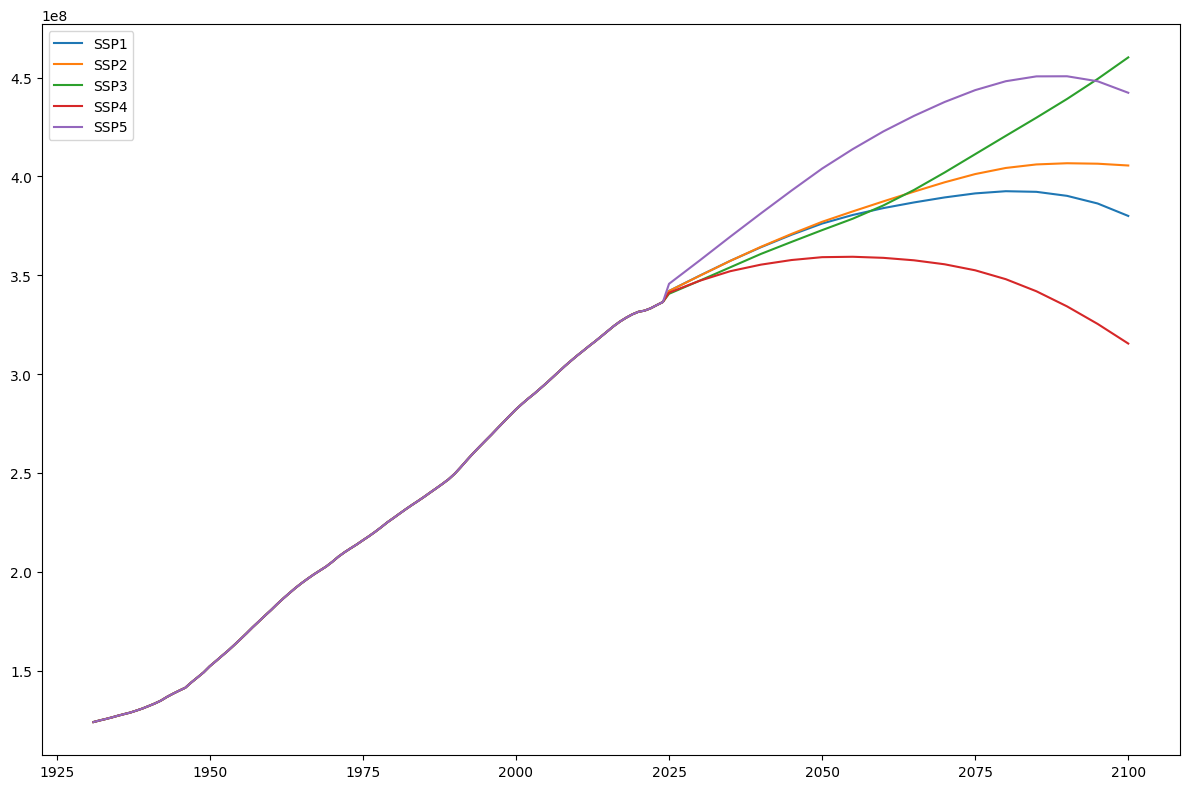

In [3]:
plt.plot(df_population.index,df_population['pop_ssp1'], label='SSP1')
plt.plot(df_population.index,df_population['pop_ssp2'], label='SSP2')
plt.plot(df_population.index,df_population['pop_ssp3'], label='SSP3')
plt.plot(df_population.index,df_population['pop_ssp4'], label='SSP4')
plt.plot(df_population.index,df_population['pop_ssp5'], label='SSP5')
plt.legend()

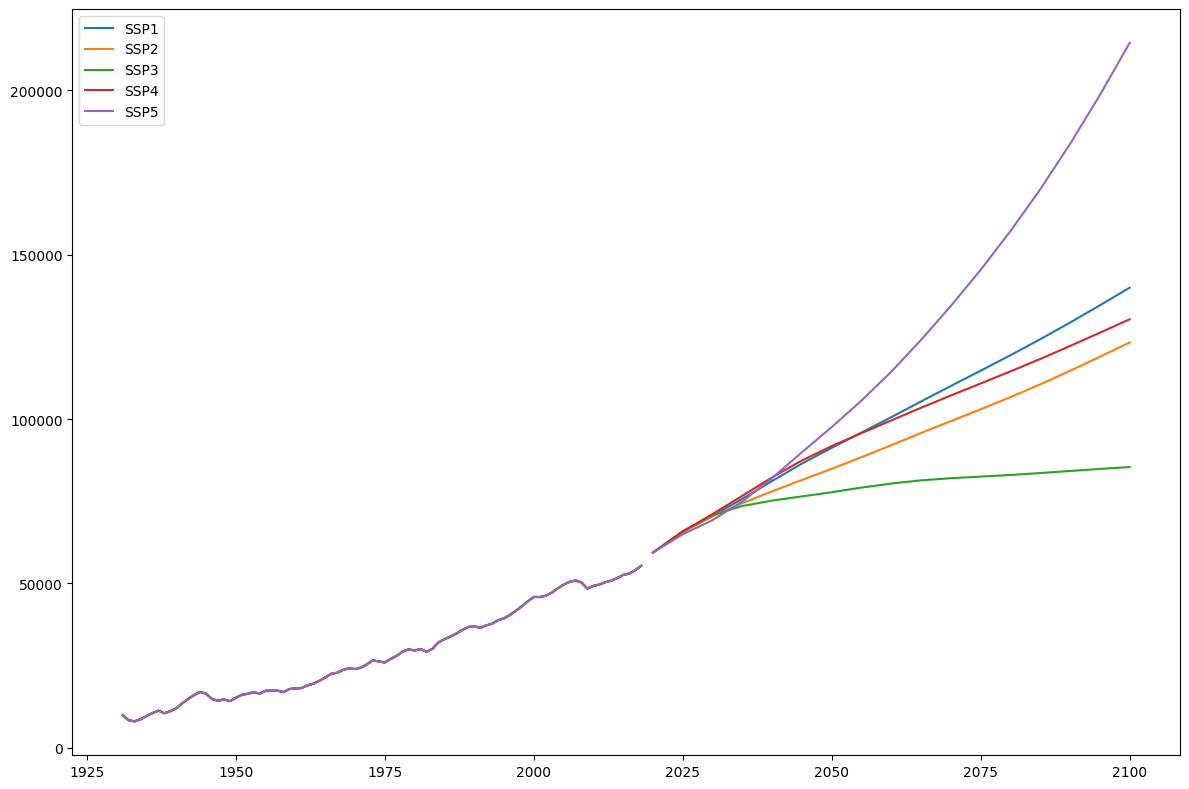

In [4]:
plt.plot(df_gdp.index,df_gdp['gdp_ssp1'], label='SSP1')
plt.plot(df_gdp.index,df_gdp['gdp_ssp2'], label='SSP2')
plt.plot(df_gdp.index,df_gdp['gdp_ssp3'], label='SSP3')
plt.plot(df_gdp.index,df_gdp['gdp_ssp4'], label='SSP4')
plt.plot(df_gdp.index,df_gdp['gdp_ssp5'], label='SSP5')
plt.legend()

## Perform MFA

In [5]:
## Define survival Function
def generate_lt(type, par1, par2):
    ''' Normal: par1  = mean, par2 = std. dev
        Weibull: par1 = shape, par2 = scale'''
    if type=='Normal':
        # Normal
        lt = {'Type': type, 'Mean': np.array([par1] * len(years)), 'StdDev': par2}
    elif type=='Weibull':
        # Weibull 
            lt = {'Type': type, 'Shape': np.array([par1]), 'Scale': np.array([par2])}
    return lt   

# For testing shapes
x=np.arange(1,170)
def weib(x,n,a):
    return (a/n) * (x/n)**(a-1) * np.exp(-(x/n)**a)

Text(0.5, 0, 'Age to Failuire')

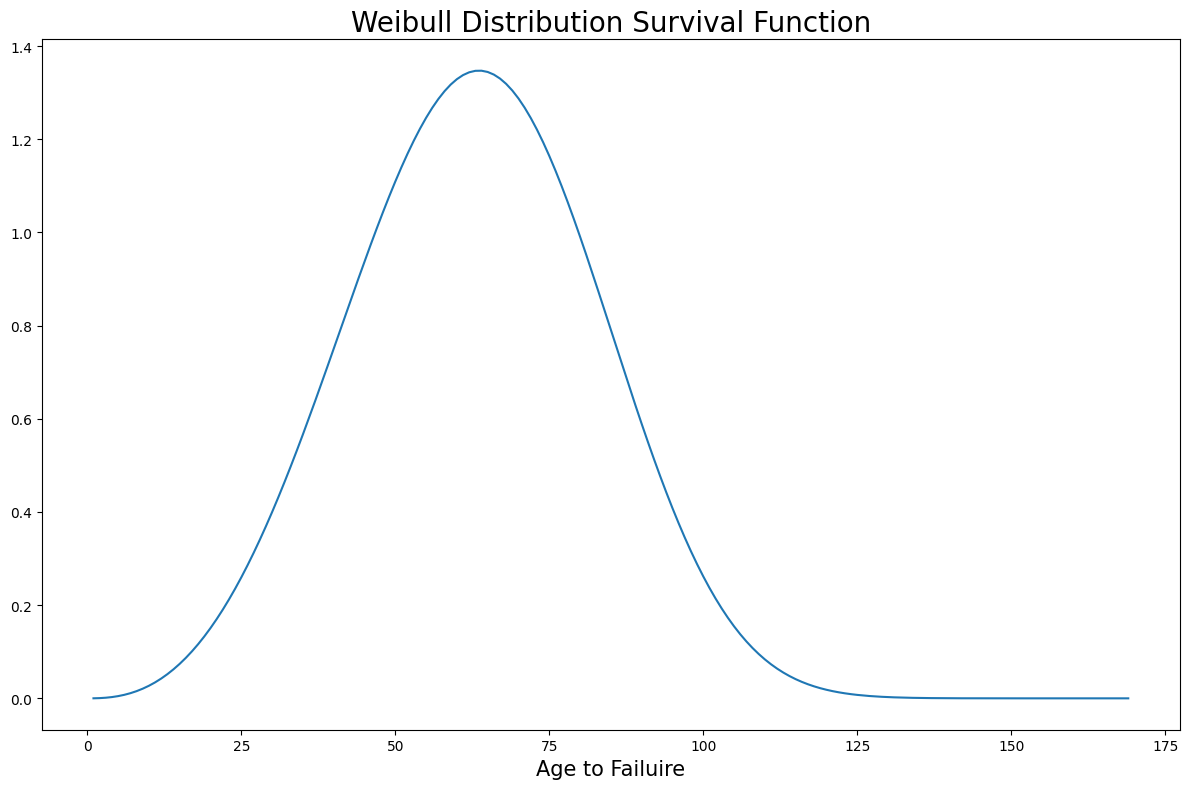

In [11]:
## See weibull shapes
lt_buildings = generate_lt('Weibull',par1=3.5,par2=70)

plt.plot(x, weib(x, lt_buildings['Scale'][0], lt_buildings['Shape'][0])*lt_buildings['Scale'][0])
plt.title('Weibull Distribution Survival Function', fontsize = 20)
plt.xlabel('Age to Failuire', fontsize = 15)

In [52]:
## Get params
years = df_steel_forecast.index

years = np.array(years)
n_years = len(years)

base_shape = 3.5
base_scale = 70
change_year = 2024
n_scenarios = 20


In [56]:
def build_lifetime_scenarios(inflow_series, years, base_shape=3.5, base_scale=69,
                               change_year=2024, n_scenarios=21):
    """
    Builds a dict of DSM results, one per lifetime scale scenario,
    for a given inflow series (e.g. ssp1, ssp2, ssp3...).
    """
    results = {}
    n_years = len(years)

    for i in range(n_scenarios):
        new_scale = base_scale + (i + 1)  # 70, 71, ..., 90

        shape_array = np.full(n_years, base_shape)
        scale_array = np.where(years <= change_year, base_scale, new_scale)

        steel_DSM = dsm.DynamicStockModel(
            t=years,
            i=np.array(inflow_series),
            lt={'Type': 'Weibull', 'Shape': shape_array, 'Scale': scale_array}
        )

        stock_by_cohort = steel_DSM.compute_s_c_inflow_driven()
        CheckStr = steel_DSM.dimension_check()
        S_steel = steel_DSM.compute_stock_total()
        O_C = steel_DSM.compute_o_c_from_s_c()
        DS_steel = steel_DSM.compute_stock_change()
        O_steel = steel_DSM.compute_outflow_total()

        results[f'scale_{new_scale}'] = {
            'dsm': steel_DSM,
            'stock_by_cohort': stock_by_cohort,
            'check': CheckStr,
            'S_steel': S_steel,
            'O_C': O_C,
            'DS_steel': DS_steel,
            'O_steel': O_steel,
            'lifetime_scale': new_scale,
        }

    return results

In [57]:
scenario_results_low  = build_lifetime_scenarios(df_steel_forecast['ssp3'], years)
scenario_results_mid  = build_lifetime_scenarios(df_steel_forecast['ssp2'], years)
scenario_results_high = build_lifetime_scenarios(df_steel_forecast['ssp4'], years)

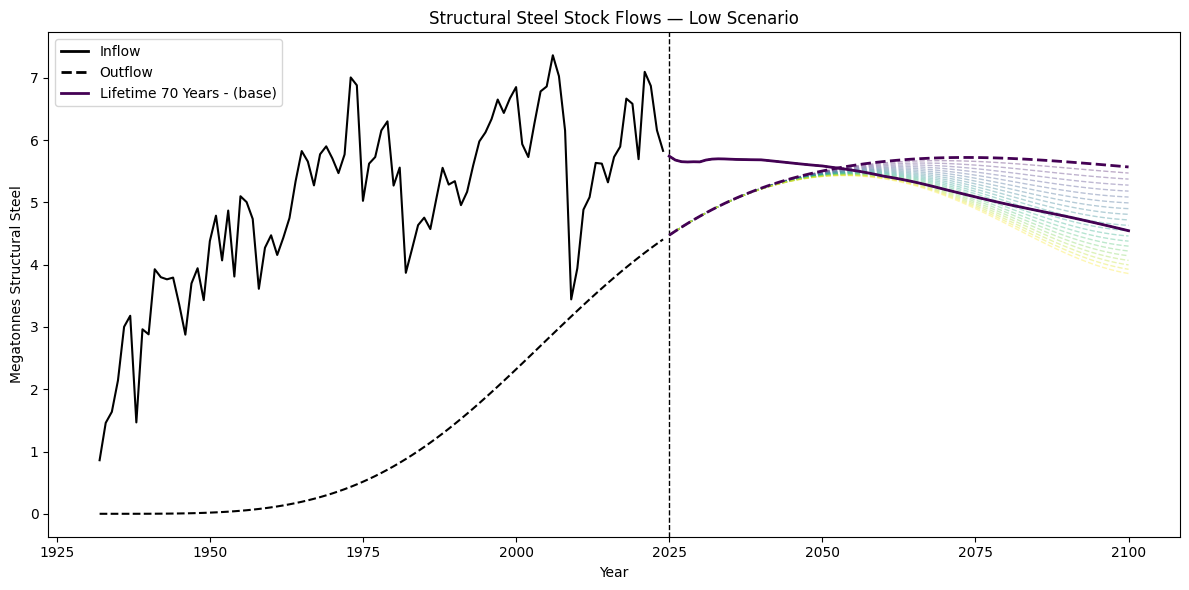

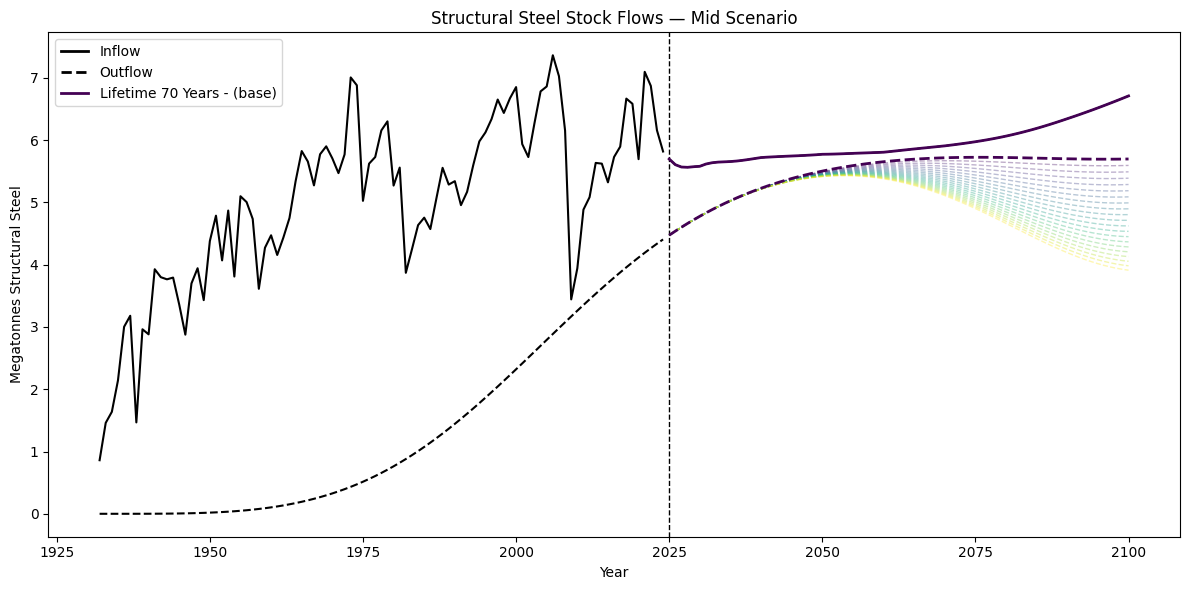

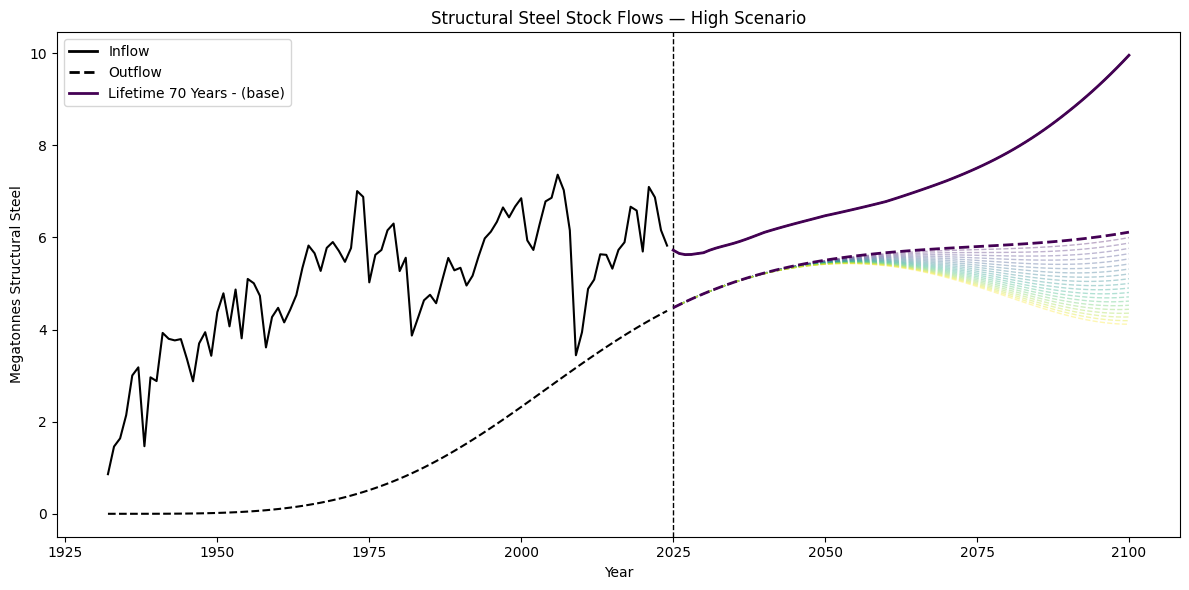

In [71]:
def plot_lifetime_scenarios(scenario_results, inflow_series, years, title,
                              change_year=2024, base_scale=70,
                              historical_outflow=None):
    fig, ax = plt.subplots(figsize=(12, 6))
    scale_values = sorted(
        int(k.split('_')[1]) for k in scenario_results.keys()
    )
    colors = cm.viridis(np.linspace(0, 1, len(scale_values)))
    inflow = np.array(inflow_series)
    mask = years > change_year
    for idx, scale in enumerate(scale_values):
        result = scenario_results[f'scale_{scale}']
        outflow = result['O_steel']
        is_base = (scale == base_scale)
        alpha = 1.0 if is_base else 0.35
        lw = 2.0 if is_base else 1.0
        zorder = 10 if is_base else 2
        ax.plot(years[mask], inflow[mask], color=colors[idx], alpha=alpha,
                linewidth=lw, zorder=zorder, linestyle='-')
        ax.plot(years[mask], outflow[mask], color=colors[idx], alpha=alpha,
                linewidth=lw, zorder=zorder, linestyle='--')

    hist_mask = years <= change_year
    ax.plot(years[hist_mask], inflow[hist_mask],
            color='black', linewidth=1.5, zorder=5)
    if historical_outflow is not None:
        # historical_outflow is already pre-sliced to the historical period — don't mask again
        ax.plot(years[hist_mask], np.array(historical_outflow),
                color='black', linestyle='--', linewidth=1.5, zorder=5)

    ax.axvline(change_year + 1, color='black', linestyle='--', linewidth=1)
    ax.set_xlabel('Year')
    ax.set_ylabel('Megatonnes Structural Steel')
    ax.set_title(title)
    legend_elements = [
        Line2D([0], [0], color='black', lw=2, label='Inflow'),
        Line2D([0], [0], color='black', lw=2, linestyle='--', label='Outflow'),
        Line2D([0], [0], color=colors[scale_values.index(base_scale)], lw=2,
               alpha=1.0, label=f'Lifetime {base_scale} Years - (base)'),
    ]
    ax.legend(handles=legend_elements, loc='upper left')
    plt.tight_layout()
    plt.show()
    return fig, ax


### Define Historic Steel Outflows
O_steel_full = scenario_results_mid['scale_70']['O_steel']
hist_mask = scenario_results_mid['scale_70']['dsm'].t <= 2024
O_steel_historical = O_steel_full[hist_mask]

# --- three separate calls, one per scenario family ---
fig_low, ax_low = plot_lifetime_scenarios(
    scenario_results_low, df_steel_forecast['ssp3'], years,
    title='Structural Steel Stock Flows — Low Scenario',
    historical_outflow=O_steel_historical
)

fig_mid, ax_mid = plot_lifetime_scenarios(
    scenario_results_mid, df_steel_forecast['ssp2'], years,
    title='Structural Steel Stock Flows — Mid Scenario',
    historical_outflow=O_steel_historical
)

fig_high, ax_high = plot_lifetime_scenarios(
    scenario_results_high, df_steel_forecast['ssp4'], years,
    title='Structural Steel Stock Flows — High Scenario',
    historical_outflow=O_steel_historical
)


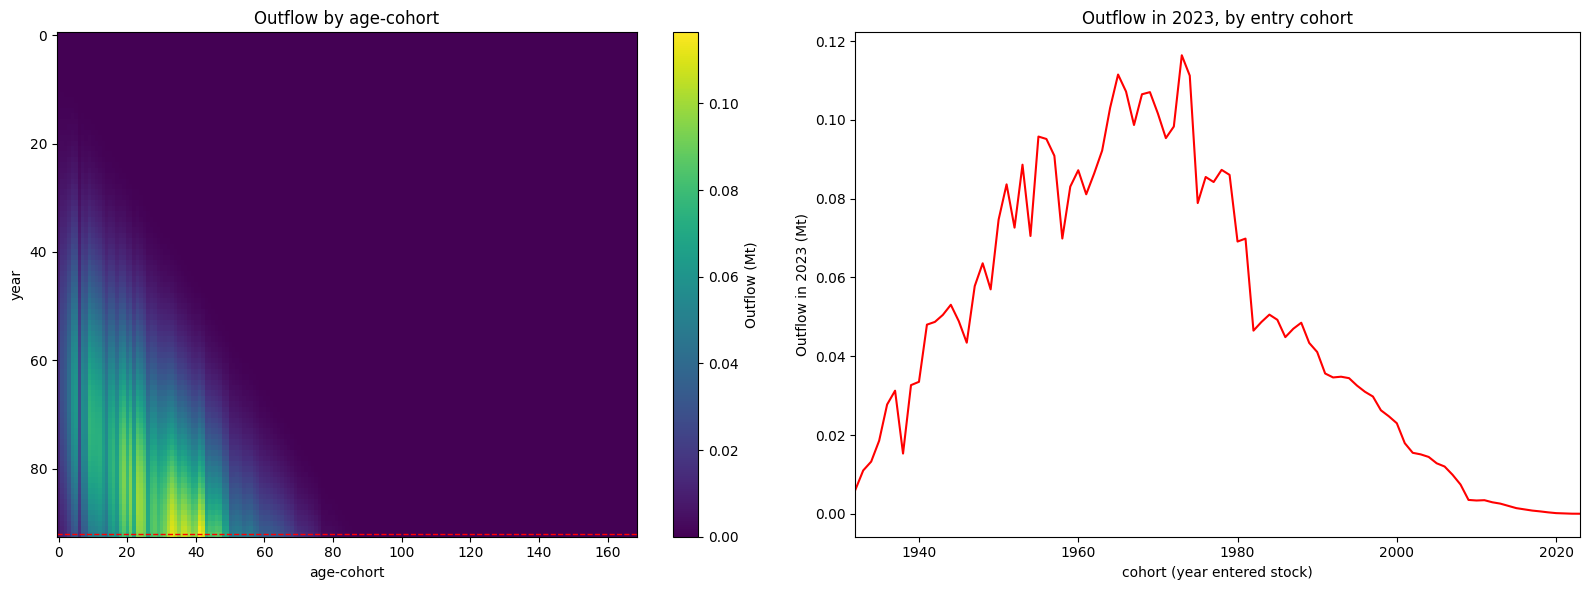

In [84]:
O_C_hist = scenario_results_mid['scale_70']['O_C'][hist_mask]  # shape (93, 169)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Left: heatmap (same as before) ---
im = ax1.imshow(O_C_hist, interpolation='nearest', aspect='auto', cmap='viridis')
ax1.set_xlabel('age-cohort')
ax1.set_ylabel('year')
ax1.set_title('Outflow by age-cohort')
fig.colorbar(im, ax=ax1, label='Outflow (Mt)')

# highlight the row we're slicing out on the right
last_row_idx = O_C_hist.shape[0] - 1  # index for 2023 (last historical year)
ax1.axhline(last_row_idx, color='red', linestyle='--', linewidth=1)

# --- Right: single-year cohort slice ---
cohort_years = years  # full 1931-2100 cohort axis, length 169
outflow_2023 = O_C_hist[last_row_idx, :]

ax2.plot(cohort_years, outflow_2023, color='red', linewidth=1.5)
ax2.set_xlabel('cohort (year entered stock)')
ax2.set_ylabel('Outflow in 2023 (Mt)')
ax2.set_title('Outflow in 2023, by entry cohort')
ax2.set_xlim(cohort_years.min(), 2023)  # no point showing cohorts that don't exist yet

plt.tight_layout()
plt.show()

From here I need to calculate what percentage of outflow came from pre-1960 in 2023

### Convert to Tidy Data

In [86]:
def tidy_scenario_results(scenario_results, years, inflow_series=None):
    """
    Converts a scenario_results dict into two tidy DataFrames:
      - df_annual: one row per (scale, year, variable) for 1D series
                   (Inflow, Stock, Outflow, Stock_Change)
      - df_cohort: one row per (scale, year, cohort, variable) for 2D series
                   (Stock_by_cohort, Outflow_by_cohort)
    """
    annual_rows = []
    cohort_rows = []

    for scale_key, result in scenario_results.items():
        scale = result['lifetime_scale']

        # --- 1D annual series ---
        annual_vars = {
            'Stock': result['S_steel'],
            'Outflow': result['O_steel'],
            'Stock_Change': result['DS_steel'],
        }
        if inflow_series is not None:
            annual_vars['Inflow'] = np.array(inflow_series)

        for var_name, values in annual_vars.items():
            values = np.asarray(values)
            for yr, val in zip(years, values):
                annual_rows.append({
                    'scale': scale,
                    'year': yr,
                    'variable': var_name,
                    'value': val,
                })

        # --- 2D cohort-indexed series (year x cohort) ---
        cohort_vars = {
            'Stock_by_cohort': result['stock_by_cohort'],
            'Outflow_by_cohort': result['O_C'],
        }
        for var_name, matrix in cohort_vars.items():
            matrix = np.asarray(matrix)
            for yr_idx, yr in enumerate(years):
                for cohort_idx, cohort_yr in enumerate(years):
                    val = matrix[yr_idx, cohort_idx]
                    if val == 0:
                        continue  # skip structural zeros to keep table size manageable
                    cohort_rows.append({
                        'scale': scale,
                        'year': yr,
                        'cohort': cohort_yr,
                        'variable': var_name,
                        'value': val,
                    })

    df_annual = pd.DataFrame(annual_rows)
    df_cohort = pd.DataFrame(cohort_rows)
    return df_annual, df_cohort


In [87]:
df_tidy_low, df_cohort_low = tidy_scenario_results(scenario_results_low, years, inflow_series=df_steel_forecast['ssp3'])
df_tidy_mid, df_cohort_mid = tidy_scenario_results(scenario_results_mid, years, inflow_series=df_steel_forecast['ssp2'])
df_tidy_high, df_cohort_high = tidy_scenario_results(scenario_results_high, years, inflow_series=df_steel_forecast['ssp4'])

### Percent demand Satisfied by Outflows

In [123]:
def compute_outflow_inflow_ratio(df_tidy, start_year=2024, end_year=2100):
    """
    Pivots a tidy annual DataFrame (columns: scale, year, variable, value)
    to compute Outflow/Inflow ratio per (scale, year).
    """
    pivoted = df_tidy[df_tidy['variable'].isin(['Inflow', 'Outflow'])].pivot_table(
        index=['scale', 'year'], columns='variable', values='value'
    ).reset_index()

    pivoted['ratio'] = pivoted['Outflow'] / pivoted['Inflow']

    # restrict to the display window
    pivoted = pivoted[(pivoted['year'] >= start_year) & (pivoted['year'] <= end_year)]


    return pivoted


def plot_outflow_inflow_ratio(df_tidy, title, base_scale=70, start_year=2024, end_year=2100,
                                annotate_years=(2050, 2075, 2100)):
    ratio_df = compute_outflow_inflow_ratio(df_tidy, start_year=start_year, end_year=end_year)
    scales = sorted(ratio_df['scale'].unique())
    colors = cm.viridis(np.linspace(0, 1, len(scales)))

    fig, ax = plt.subplots(figsize=(10, 5))

    for idx, scale in enumerate(scales):
        subset = ratio_df[ratio_df['scale'] == scale].sort_values('year')
        is_base = (scale == base_scale)
        alpha = 1.0 if is_base else 0.4
        lw = 2.0 if is_base else 1.0
        zorder = 10 if is_base else 2

        ax.plot(subset['year'], subset['ratio'] * 100,
                color=colors[idx], alpha=alpha, linewidth=lw, zorder=zorder,
                label=f'Base - 70 Yr Lifetime' if is_base else None)

    # ax.set_ylabel('Percent of Inflows met by Outflows')
    ax.set_xlabel('Year')
    ax.set_title(title)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}%'))
    ax.set_xlim(start_year, end_year)
    ax.legend(title='Scenario', loc='upper left')

    # --- annotate min/max ratio at each specified year ---
    for yr in annotate_years:
        year_slice = ratio_df[ratio_df['year'] == yr]
        if year_slice.empty:
            continue

        max_row = year_slice.loc[year_slice['ratio'].idxmax()]
        min_row = year_slice.loc[year_slice['ratio'].idxmin()]

        max_pct = max_row['ratio'] * 100
        min_pct = min_row['ratio'] * 100

        box_text = f"{yr}\nHigh: {max_pct:.0f}%\nLow: {min_pct:.0f}%"

        ax.annotate(
            box_text,
            xy=(yr, max_pct),
            xytext=(yr, min_pct - 8),  # offset above the highest line at that year
            ha='center', va='bottom', fontsize=8,
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='gray', alpha=0.9),
            zorder=20,
        )

        ax.vlines(
            x = yr, 
            ymin=min_pct, 
            ymax=max_pct, 
            color='black', 
            linestyle='-', 
            linewidth=2, 
            alpha=1, 
            zorder=1)

        ax.hlines(
            y=[min_pct, max_pct],
            xmin=yr - 0.5,
            xmax=yr + 0.5,
            color='black',
            linewidth=2,
            alpha=1,
            zorder=15,
    )

    plt.tight_layout()
    plt.show()
    return fig, ax



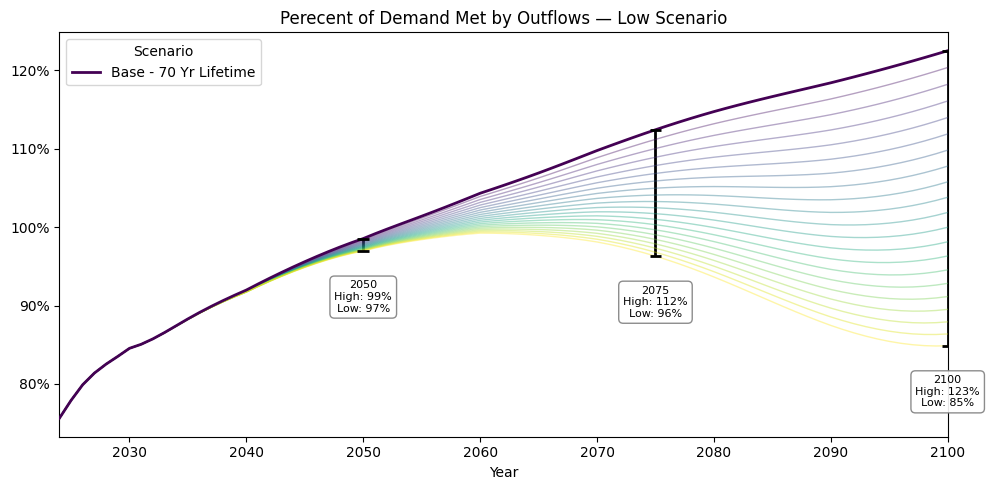

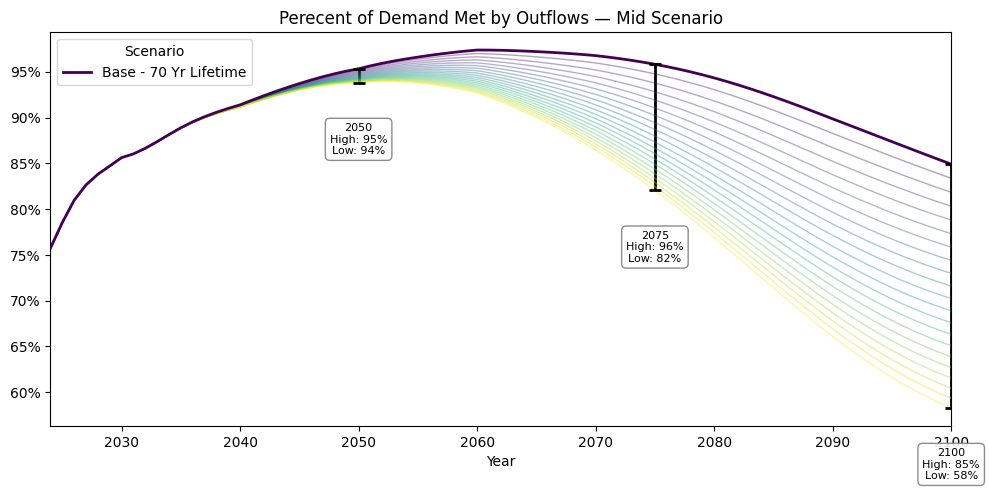

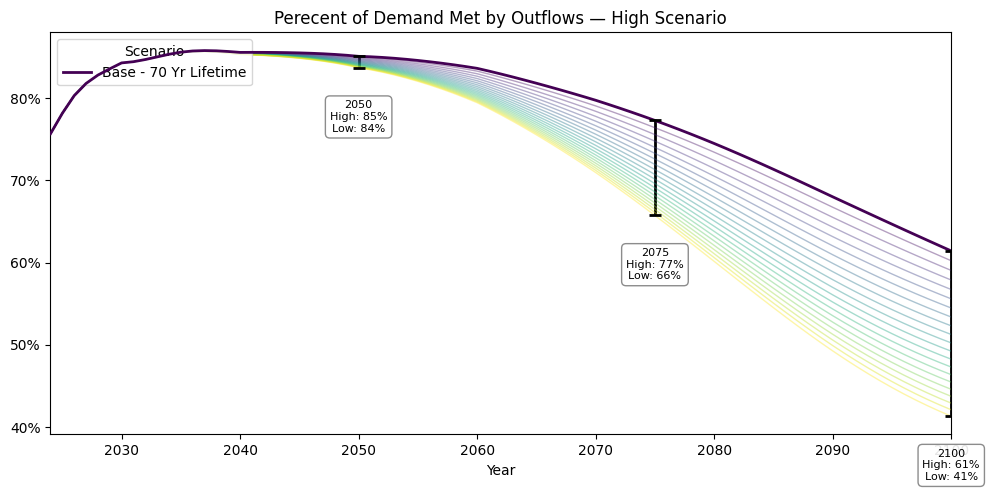

In [124]:
# --- three separate plots ---
fig_low, ax_low = plot_outflow_inflow_ratio(df_tidy_low, title='Perecent of Demand Met by Outflows — Low Scenario')
fig_mid, ax_mid = plot_outflow_inflow_ratio(df_tidy_mid, title='Perecent of Demand Met by Outflows — Mid Scenario')
fig_high, ax_high = plot_outflow_inflow_ratio(df_tidy_high, title='Perecent of Demand Met by Outflows — High Scenario')

### Old MFA

In [ ]:
## Perform MFA ssp2

# steel_DSM_ssp2 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp2']), 
#                                   lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
#                                         'Scale': np.array([85]) })

# stock_by_cohort =  steel_DSM_ssp2.compute_s_c_inflow_driven()
# CheckStr = steel_DSM_ssp2.dimension_check()
# S_steel = steel_DSM_ssp2.compute_stock_total() 
# O_C = steel_DSM_ssp2.compute_o_c_from_s_c()
# DS_steel = steel_DSM_ssp2.compute_stock_change()
# O_steel = steel_DSM_ssp2.compute_outflow_total()

In [ ]:
## Perform MFA ssp3

# steel_DSM_ssp3 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp3']), 
#                                   lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
#                                         'Scale': np.array([85]) })

# stock_by_cohort =  steel_DSM_ssp3.compute_s_c_inflow_driven()
# CheckStr = steel_DSM_ssp3.dimension_check()
# S_steel = steel_DSM_ssp3.compute_stock_total() 
# O_C = steel_DSM_ssp3.compute_o_c_from_s_c()
# DS_steel = steel_DSM_ssp3.compute_stock_change()
# O_steel = steel_DSM_ssp3.compute_outflow_total()

In [ ]:
## Perform MFA ssp4

# steel_DSM_ssp4 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp4']), 
#                                   lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
#                                         'Scale': np.array([85]) })

# stock_by_cohort =  steel_DSM_ssp4.compute_s_c_inflow_driven()
# CheckStr = steel_DSM_ssp4.dimension_check()
# S_steel = steel_DSM_ssp4.compute_stock_total() 
# O_C = steel_DSM_ssp4.compute_o_c_from_s_c()
# DS_steel = steel_DSM_ssp4.compute_stock_change()
# O_steel = steel_DSM_ssp4.compute_outflow_total()

In [ ]:
## Perform MFA ssp5

# steel_DSM_ssp5 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp5']), 
#                                   lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
#                                         'Scale': np.array([85]) })

# stock_by_cohort =  steel_DSM_ssp5.compute_s_c_inflow_driven()
# CheckStr = steel_DSM_ssp5.dimension_check()
# S_steel = steel_DSM_ssp5.compute_stock_total() 
# O_C = steel_DSM_ssp5.compute_o_c_from_s_c()
# DS_steel = steel_DSM_ssp5.compute_stock_change()
# O_steel = steel_DSM_ssp5.compute_outflow_total()

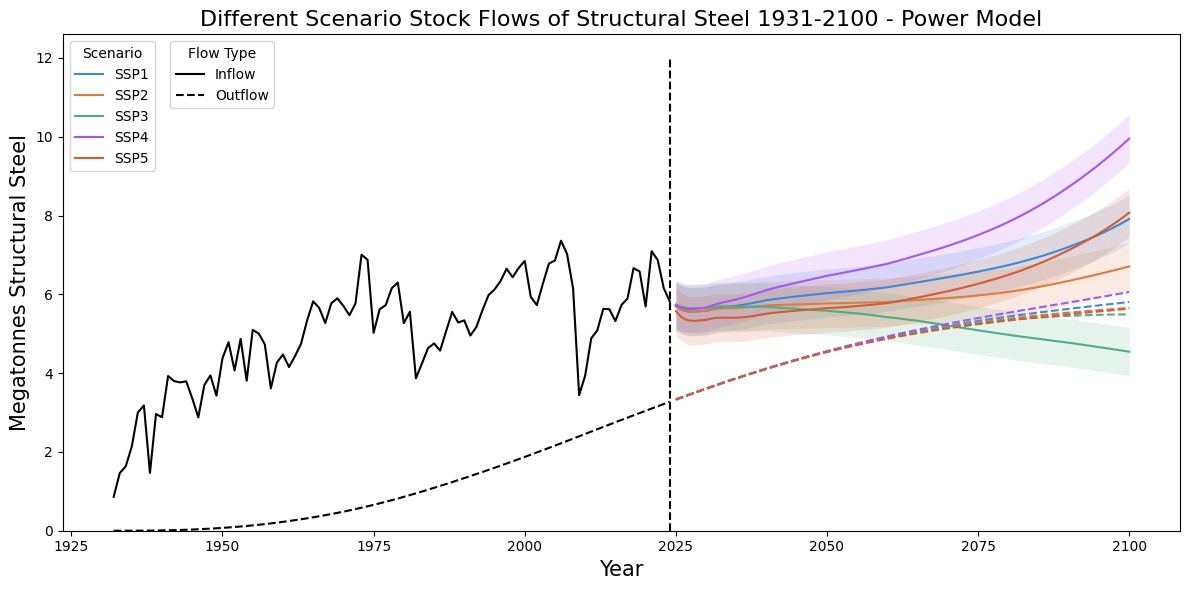

In [24]:
### Forecast with MAE bands ###

fig, ax = plt.subplots(figsize=(12,6))

ax.plot(steel_DSM_ssp1.t[:93], steel_DSM_ssp1.i[:93], color='black')
ax.plot(steel_DSM_ssp1.t[93:], steel_DSM_ssp1.i[93:], color='#378ADD')
ax.plot(steel_DSM_ssp2.t[93:], steel_DSM_ssp2.i[93:], color='#E07B3F')
ax.plot(steel_DSM_ssp3.t[93:], steel_DSM_ssp3.i[93:], color='#4CAF82')
ax.plot(steel_DSM_ssp4.t[93:], steel_DSM_ssp4.i[93:], color='#A855F7')
ax.plot(steel_DSM_ssp5.t[93:], steel_DSM_ssp5.i[93:], color='#D85A30')

ax.plot(steel_DSM_ssp1.t[:93], steel_DSM_ssp1.o[:93], color='black', ls="--")
ax.plot(steel_DSM_ssp1.t[93:], steel_DSM_ssp1.o[93:], color='#378ADD', ls="--")
ax.plot(steel_DSM_ssp2.t[93:], steel_DSM_ssp2.o[93:], color='#E07B3F', ls="--")
ax.plot(steel_DSM_ssp3.t[93:], steel_DSM_ssp3.o[93:], color='#4CAF82', ls="--")
ax.plot(steel_DSM_ssp4.t[93:], steel_DSM_ssp4.o[93:], color='#A855F7', ls="--")
ax.plot(steel_DSM_ssp5.t[93:], steel_DSM_ssp5.o[93:], color='#D85A30', ls="--")

# --- fill_between bands around each inflow line (±0.610) ---
# ax.fill_between(steel_DSM_ssp1.t[:93],
#                  steel_DSM_ssp1.i[:93] - 0.610, steel_DSM_ssp1.i[:93] + 0.610,
#                  color='black', alpha=0.15, linewidth=0)
ax.fill_between(steel_DSM_ssp1.t[93:],
                 steel_DSM_ssp1.i[93:] - 0.610, steel_DSM_ssp1.i[93:] + 0.610,
                 color='#378ADD', alpha=0.15, linewidth=0)
ax.fill_between(steel_DSM_ssp2.t[93:],
                 steel_DSM_ssp2.i[93:] - 0.610, steel_DSM_ssp2.i[93:] + 0.610,
                 color='#E07B3F', alpha=0.15, linewidth=0)
ax.fill_between(steel_DSM_ssp3.t[93:],
                 steel_DSM_ssp3.i[93:] - 0.610, steel_DSM_ssp3.i[93:] + 0.610,
                 color='#4CAF82', alpha=0.15, linewidth=0)
ax.fill_between(steel_DSM_ssp4.t[93:],
                 steel_DSM_ssp4.i[93:] - 0.610, steel_DSM_ssp4.i[93:] + 0.610,
                 color='#A855F7', alpha=0.15, linewidth=0)
ax.fill_between(steel_DSM_ssp5.t[93:],
                 steel_DSM_ssp5.i[93:] - 0.610, steel_DSM_ssp5.i[93:] + 0.610,
                 color='#D85A30', alpha=0.15, linewidth=0)

ax.plot([2024,2024],[0,12], color='k', linestyle='--')
plt.xlabel('Year', fontsize=15)
plt.ylabel('Megatonnes Structural Steel', fontsize=15)
plt.title('Different Scenario Stock Flows of Structural Steel 1931-2100 - Power Model', fontsize=16)

scenario_handles = [
    mlines.Line2D([], [], color='#378ADD', linestyle='-', label='SSP1'),
    mlines.Line2D([], [], color='#E07B3F', linestyle='-', label='SSP2'),
    mlines.Line2D([], [], color='#4CAF82', linestyle='-', label='SSP3'),
    mlines.Line2D([], [], color='#A855F7', linestyle='-', label='SSP4'),
    mlines.Line2D([], [], color='#D85A30', linestyle='-', label='SSP5'),
]

leg1 = ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')
ax.add_artist(leg1)

flow_handles = [
    mlines.Line2D([], [], color='black', linestyle='-', label='Inflow'),
    mlines.Line2D([], [], color='black', linestyle='--', label='Outflow'),
]

ax.set_ylim(0,)
ax.legend(handles=flow_handles, title='Flow Type', loc='upper left', bbox_to_anchor=(0.09, 1))
plt.show()

In [ ]:
# start_year = 1931
# n_years = len(steel_DSM_ssp1.t)
# years = np.arange(start_year, start_year + n_years)

# # Build all SSP flow dataframes
# flow_dfs = {}

# for s in range(1, 6):   # SSP1–SSP5
#     model = globals()[f"steel_DSM_ssp{s}"]   # get steel_DSM_ssp1, etc.

#     df = pd.DataFrame({
#         f"inflow_ssp{s}":  model.i,
#         f"outflow_ssp{s}": model.o,
#     }, index=years)

#     df.index.name = "Year"

#     flow_dfs[f"ssp{s}"] = df

# all_flows = pd.concat(flow_dfs.values(), axis=1)

In [ ]:
# all_flows.loc[2024]

inflow_ssp1     5.693083
outflow_ssp1    3.329969
inflow_ssp2     5.694787
outflow_ssp2    3.329969
inflow_ssp3     5.741518
outflow_ssp3    3.329969
inflow_ssp4     5.722451
outflow_ssp4    3.329969
inflow_ssp5     5.574647
outflow_ssp5    3.329968
Name: 2024, dtype: float64

Deconstruction / demolition emissions excluded, assumed to be the same for this. However, future versions of this model should note that deconstruction seemingly tends to have lower emissions associated with it

In [19]:
# total_flows['flows delta'] = total_flows['Total Inflow'] - total_flows['Total Outflow']
# total_flows['demand percentage'] = total_flows['Total Outflow'] / total_flows['Total Inflow']

In [ ]:
# all_flows['demand percentage_ssp1'] = all_flows['outflow_ssp1'] / all_flows['inflow_ssp1']
# all_flows['demand percentage_ssp2'] = all_flows['outflow_ssp2'] / all_flows['inflow_ssp2']
# all_flows['demand percentage_ssp3'] = all_flows['outflow_ssp3'] / all_flows['inflow_ssp3']
# all_flows['demand percentage_ssp4'] = all_flows['outflow_ssp4'] / all_flows['inflow_ssp4']
# all_flows['demand percentage_ssp5'] = all_flows['outflow_ssp5'] / all_flows['inflow_ssp5']


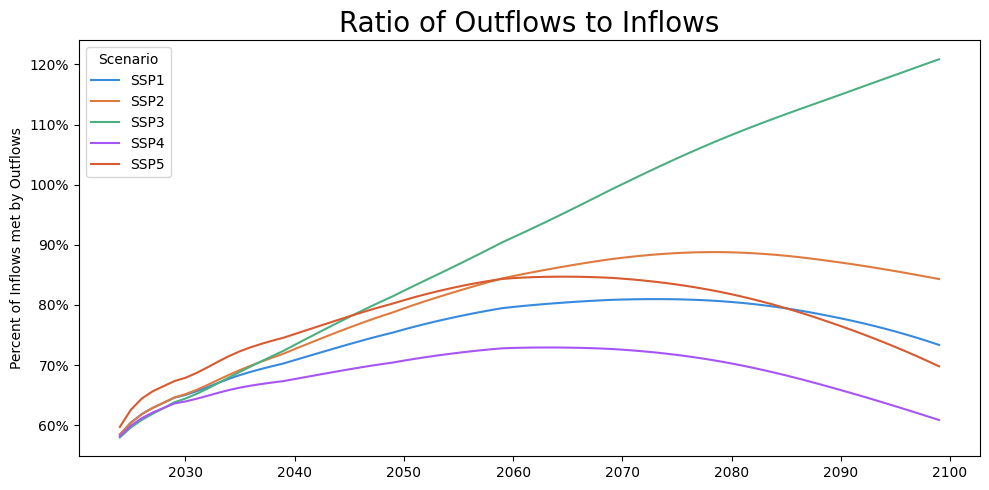

In [ ]:
# fig,ax = plt.subplots(figsize = (10,5))

# years = all_flows.loc[2024:2100].index
# ax.plot(years, all_flows['demand percentage_ssp1'].loc[2024:2100], color = '#378ADD')
# ax.plot(years, all_flows['demand percentage_ssp2'].loc[2024:2100], color = '#E07B3F')
# ax.plot(years, all_flows['demand percentage_ssp3'].loc[2024:2100], color = '#4CAF82')
# ax.plot(years, all_flows['demand percentage_ssp4'].loc[2024:2100], color = '#A855F7')
# ax.plot(years, all_flows['demand percentage_ssp5'].loc[2024:2100], color = '#D85A30')

# plt.ylabel('Percent of Inflows met by Outflows')
# plt.title('Ratio of Outflows to Inflows', fontsize = 20)
# scenario_handles = [
#     mlines.Line2D([], [], color='#378ADD',        linestyle='-', label='SSP1'),
#     mlines.Line2D([], [], color='#E07B3F',       linestyle='-', label='SSP2'),
#     mlines.Line2D([], [], color='#4CAF82',      linestyle='-', label='SSP3'),
#     mlines.Line2D([], [], color='#A855F7',      linestyle='-', label='SSP4'),
#     mlines.Line2D([], [], color='#D85A30',         linestyle='-', label='SSP5'),
# ]

# ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
# ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')

## Scenario Analysis of Reuse Rates and Green Steel adoption

In [126]:
## Make QMC Ceilings

# Fixed, hand-adjustable curve-shape parameters — not sampled
G_reuse, M_reuse = 0.15, 2055   # adoption speed / inflection year for reuse
G_green, M_green = 0.15, 2055   # adoption speed / inflection year for green steel

def generate_qmc_ceilings(n_samples=1000, seed=42):
    """
    Samples only the long-run ceilings (B) for reuse and green-steel adoption,
    each ranging 0-100%, independently of one another. A is fixed at 0,
    G and M are fixed constants set separately.
    """
    d = 2  # B_reuse, B_green
    sampler = qmc.Sobol(d=d, scramble=True, seed=seed)
    m = int(np.ceil(np.log2(n_samples)))
    sample_unit = sampler.random_base2(m=m)[:n_samples]

    df_params = pd.DataFrame(sample_unit, columns=['B_reuse', 'B_green'])
    df_params['A_reuse'] = 0.0
    df_params['A_green'] = 0.0
    df_params['G_reuse'] = G_reuse
    df_params['M_reuse'] = M_reuse
    df_params['G_green'] = G_green
    df_params['M_green'] = M_green
    df_params['draw_id'] = np.arange(n_samples)
    return df_params


param_df = generate_qmc_ceilings(n_samples=1000)
param_df.head()

,B_reuse,B_green,A_reuse,A_green,G_reuse,M_reuse,G_green,M_green,draw_id
0,0.431029,0.814368,0.0,0.0,0.15,2055,0.15,2055,0
1,0.961579,0.311410,0.0,0.0,0.15,2055,0.15,2055,1
2,0.564532,0.597834,0.0,0.0,0.15,2055,0.15,2055,2
3,0.035047,0.026509,0.0,0.0,0.15,2055,0.15,2055,3
4,0.238067,0.639698,0.0,0.0,0.15,2055,0.15,2055,4


In [127]:
### Define Scenarios

def logistic_curve(t, A, B, G, M):
    return A + (B - A) / (1 + np.exp(-G * (t - M)))

def run_qmc_scenarios(scenario_results, inflow_series, years, param_df,
                       change_year=2024, end_year=2100):
    """
    For each lifetime scale in scenario_results, applies all 1000 QMC draws
    (B_reuse, B_green ceilings; fixed A/G/M) to compute:
      - reuse_rate(t) and reused_outflow(t)
      - production_demand(t) = max(demand_total(t) - reused_outflow(t), 0)
      - green_share(t) and the green/conventional split of production_demand
    Fully vectorized: one (n_draws x n_years) array per scale, no per-draw loop.
    """
    years = np.array(years)
    mask = (years >= change_year) & (years <= end_year)
    t = years[mask]                      # shape (n_years,)
    demand_total = np.array(inflow_series)[mask]   # shape (n_years,)

    # param arrays, reshaped to broadcast against (n_draws, n_years)
    A_r = param_df['A_reuse'].values[:, None]
    B_r = param_df['B_reuse'].values[:, None]
    G_r = param_df['G_reuse'].values[:, None]
    M_r = param_df['M_reuse'].values[:, None]

    A_g = param_df['A_green'].values[:, None]
    B_g = param_df['B_green'].values[:, None]
    G_g = param_df['G_green'].values[:, None]
    M_g = param_df['M_green'].values[:, None]

    draw_ids = param_df['draw_id'].values
    n_draws = len(param_df)
    n_years = len(t)

    frames = []
    for scale_key, result in scenario_results.items():
        scale = result['lifetime_scale']
        outflow_total = np.array(result['O_steel'])[mask]   # shape (n_years,)

        # reuse adoption curve, applied to outflow
        reuse_rate = logistic_curve(t[None, :], A_r, B_r, G_r, M_r)   # (n_draws, n_years)
        reused_outflow = reuse_rate * outflow_total[None, :]

        # production demand = total demand minus what reuse covers, floored at 0
        production_demand = np.maximum(demand_total[None, :] - reused_outflow, 0)

        # green-steel share of that production demand
        green_share = logistic_curve(t[None, :], A_g, B_g, G_g, M_g)
        green_share = np.clip(green_share, 0, 1)
        green_production = green_share * production_demand
        conventional_production = (1 - green_share) * production_demand

        frame = pd.DataFrame({
            'scale': scale,
            'draw_id': np.repeat(draw_ids, n_years),
            'year': np.tile(t, n_draws),
            'reuse_rate': reuse_rate.ravel(),
            'reused_outflow': reused_outflow.ravel(),
            'production_demand': production_demand.ravel(),
            'green_share': green_share.ravel(),
            'green_production': green_production.ravel(),
            'conventional_production': conventional_production.ravel(),
        })
        frames.append(frame)

    return pd.concat(frames, ignore_index=True)

In [128]:
df_qmc_low  = run_qmc_scenarios(scenario_results_low,  df_steel_forecast['ssp3'], years, param_df)
df_qmc_mid  = run_qmc_scenarios(scenario_results_mid,  df_steel_forecast['ssp2'], years, param_df)
df_qmc_high = run_qmc_scenarios(scenario_results_high, df_steel_forecast['ssp4'], years, param_df)

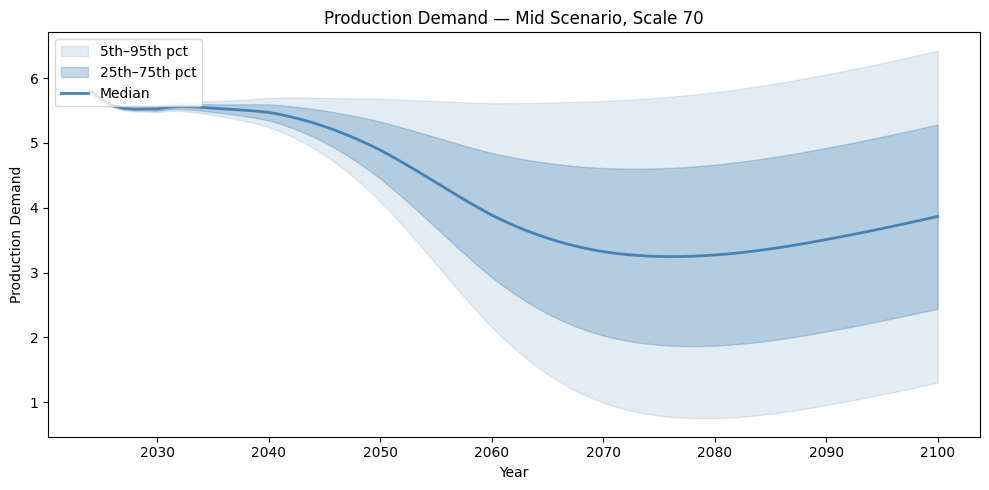

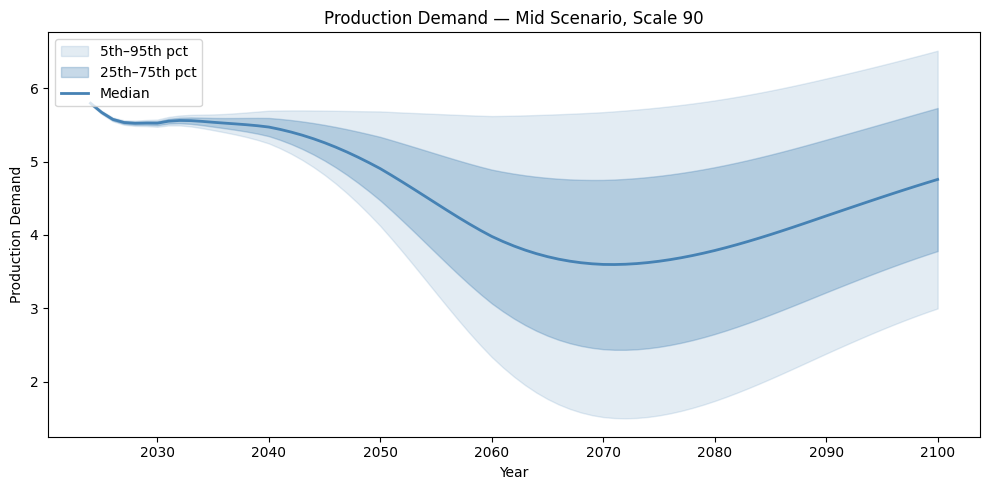

In [131]:
def plot_fan_chart(df_qmc, scale, value_col='production_demand', title=None,
                    percentiles=(5, 25, 50, 75, 95), color='steelblue'):
    """
    Plots a fan chart (percentile bands across QMC draws) for a single scale.
    """
    subset = df_qmc[df_qmc['scale'] == scale]

    # pivot so rows=year, columns=draw_id, values=value_col
    pivoted = subset.pivot(index='year', columns='draw_id', values=value_col)

    years_arr = pivoted.index.values
    pct_values = {p: pivoted.quantile(p / 100, axis=1).values for p in percentiles}

    fig, ax = plt.subplots(figsize=(10, 5))

    # shade outer band (5-95) and inner band (25-75), if present
    if 5 in pct_values and 95 in pct_values:
        ax.fill_between(years_arr, pct_values[5], pct_values[95],
                         color=color, alpha=0.15, label='5th–95th pct')
    if 25 in pct_values and 75 in pct_values:
        ax.fill_between(years_arr, pct_values[25], pct_values[75],
                         color=color, alpha=0.3, label='25th–75th pct')

    # median line
    if 50 in pct_values:
        ax.plot(years_arr, pct_values[50], color=color, linewidth=2, label='Median')

    ax.set_xlabel('Year')
    ax.set_ylabel(value_col.replace('_', ' ').title())
    ax.set_title(title or f'{value_col.replace("_", " ").title()} — Scale {scale}')
    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()
    return fig, ax


# quick check on the mid scenario, scale 70
fig, ax = plot_fan_chart(df_qmc_mid, scale=70, value_col='production_demand',
                          title='Production Demand — Mid Scenario, Scale 70')
fig, ax = plot_fan_chart(df_qmc_mid, scale=90, value_col='production_demand',
                          title='Production Demand — Mid Scenario, Scale 90')

## Make simple sankey for 2019

In [ ]:
# outflow = all_flows['outflow_ssp1'].loc[2019]*.98
# waste = all_flows['outflow_ssp1'].loc[2019]*.02
# inflow = all_flows['inflow_ssp1'].loc[2019]
# scrap = df_recycling['scrap'].loc[2019]+df_recycling['Exports'].loc[2019]-df_recycling['Imports'].loc[2019] - outflow
# virgin = 32000
# other_use = scrap + virgin - inflow
# inflow_reuse = inflow - outflow
# other_reuse = scrap + virgin - inflow_reuse

In [ ]:
# import plotly.io as pio
# pio.renderers.default = "browser"

In [ ]:
# fig = go.Figure(go.Sankey(
#     arrangement = "snap",
#     node = {
#         'label': ["Virgin", " Scrap", 'Feedstock', "EAF Processing","Fabrication","Built Environment","Construction Scrap", "Waste", "Other Use"],
#         # 'x' : [0.1, 0.1, 0.3, 0.5, 0.7, 0.8, 0.8, 0.7],
#         # 'y' : [0.7, 0.5, 0.5, 0.4, 0.4, 0.3, 0.5, 0.7]
#     },
#     link = {
#         "source" : [0,1,2,3,4,5,5,6,2],
#         "target" : [2,2,3,4,5,6,7,1,8],
#         "value" : [virgin,scrap,inflow,inflow,inflow,outflow,waste,outflow,other_use]
#     }

# ))

# fig.show()

In [ ]:
# fig = go.Figure(go.Sankey(
#     arrangement = "snap",
#     node = {
#         'label': ["Virgin", " Scrap", 'Feedstock', "EAF Processing","Fabrication","Built Environment","structural Steel Scrap", "Waste", "Other Use"],
#         # 'x' : [0.1, 0.1, 0.3, 0.5, 0.7, 0.8, 0.8, 0.7],
#         # 'y' : [0.7, 0.5, 0.5, 0.4, 0.4, 0.3, 0.5, 0.7]
#     },
#     link = {
#         "source" : [0,1,2,3,4,5,5,6,2],
#         "target" : [2,2,3,4,5,6,7,4,8],
#         "value" : [virgin,scrap,inflow_reuse,inflow_reuse,inflow,outflow,waste,outflow,other_reuse]
#     }

# ))

# fig.show()

## Static LCA

In [138]:
conventional_co2 = (.898 + ((0.026+0.0824)*1.0771))*1e6
reuse_co2 = ((0.0262+0.0824)*1.0771)*1e6
green_co2 = conventional_co2 * 0.33

In [139]:
print(conventional_co2)
print(reuse_co2)
print(green_co2)

1014757.64
116973.05999999998
334870.0212


In [137]:
def add_carbon_emissions(df_qmc, conventional_co2, reuse_co2, green_co2):
    """
    Adds a carbon_emissions column to a QMC results DataFrame using:
      emissions = conventional_production * conventional_co2
                + green_production * green_co2
                + reused_outflow * reuse_co2
    Coefficients are expected in units of tCO2 per unit of production
    (e.g. tCO2/Mt if your flows are in Mt — make sure units line up).
    """
    df_qmc = df_qmc.copy()
    df_qmc['carbon_emissions'] = (
        df_qmc['conventional_production'] * conventional_co2
        + df_qmc['green_production'] * green_co2
        + df_qmc['reused_outflow'] * reuse_co2
    )
    return df_qmc


In [140]:
df_qmc_low  = add_carbon_emissions(df_qmc_low,  conventional_co2, reuse_co2, green_co2)
df_qmc_mid  = add_carbon_emissions(df_qmc_mid,  conventional_co2, reuse_co2, green_co2)
df_qmc_high = add_carbon_emissions(df_qmc_high, conventional_co2, reuse_co2, green_co2)

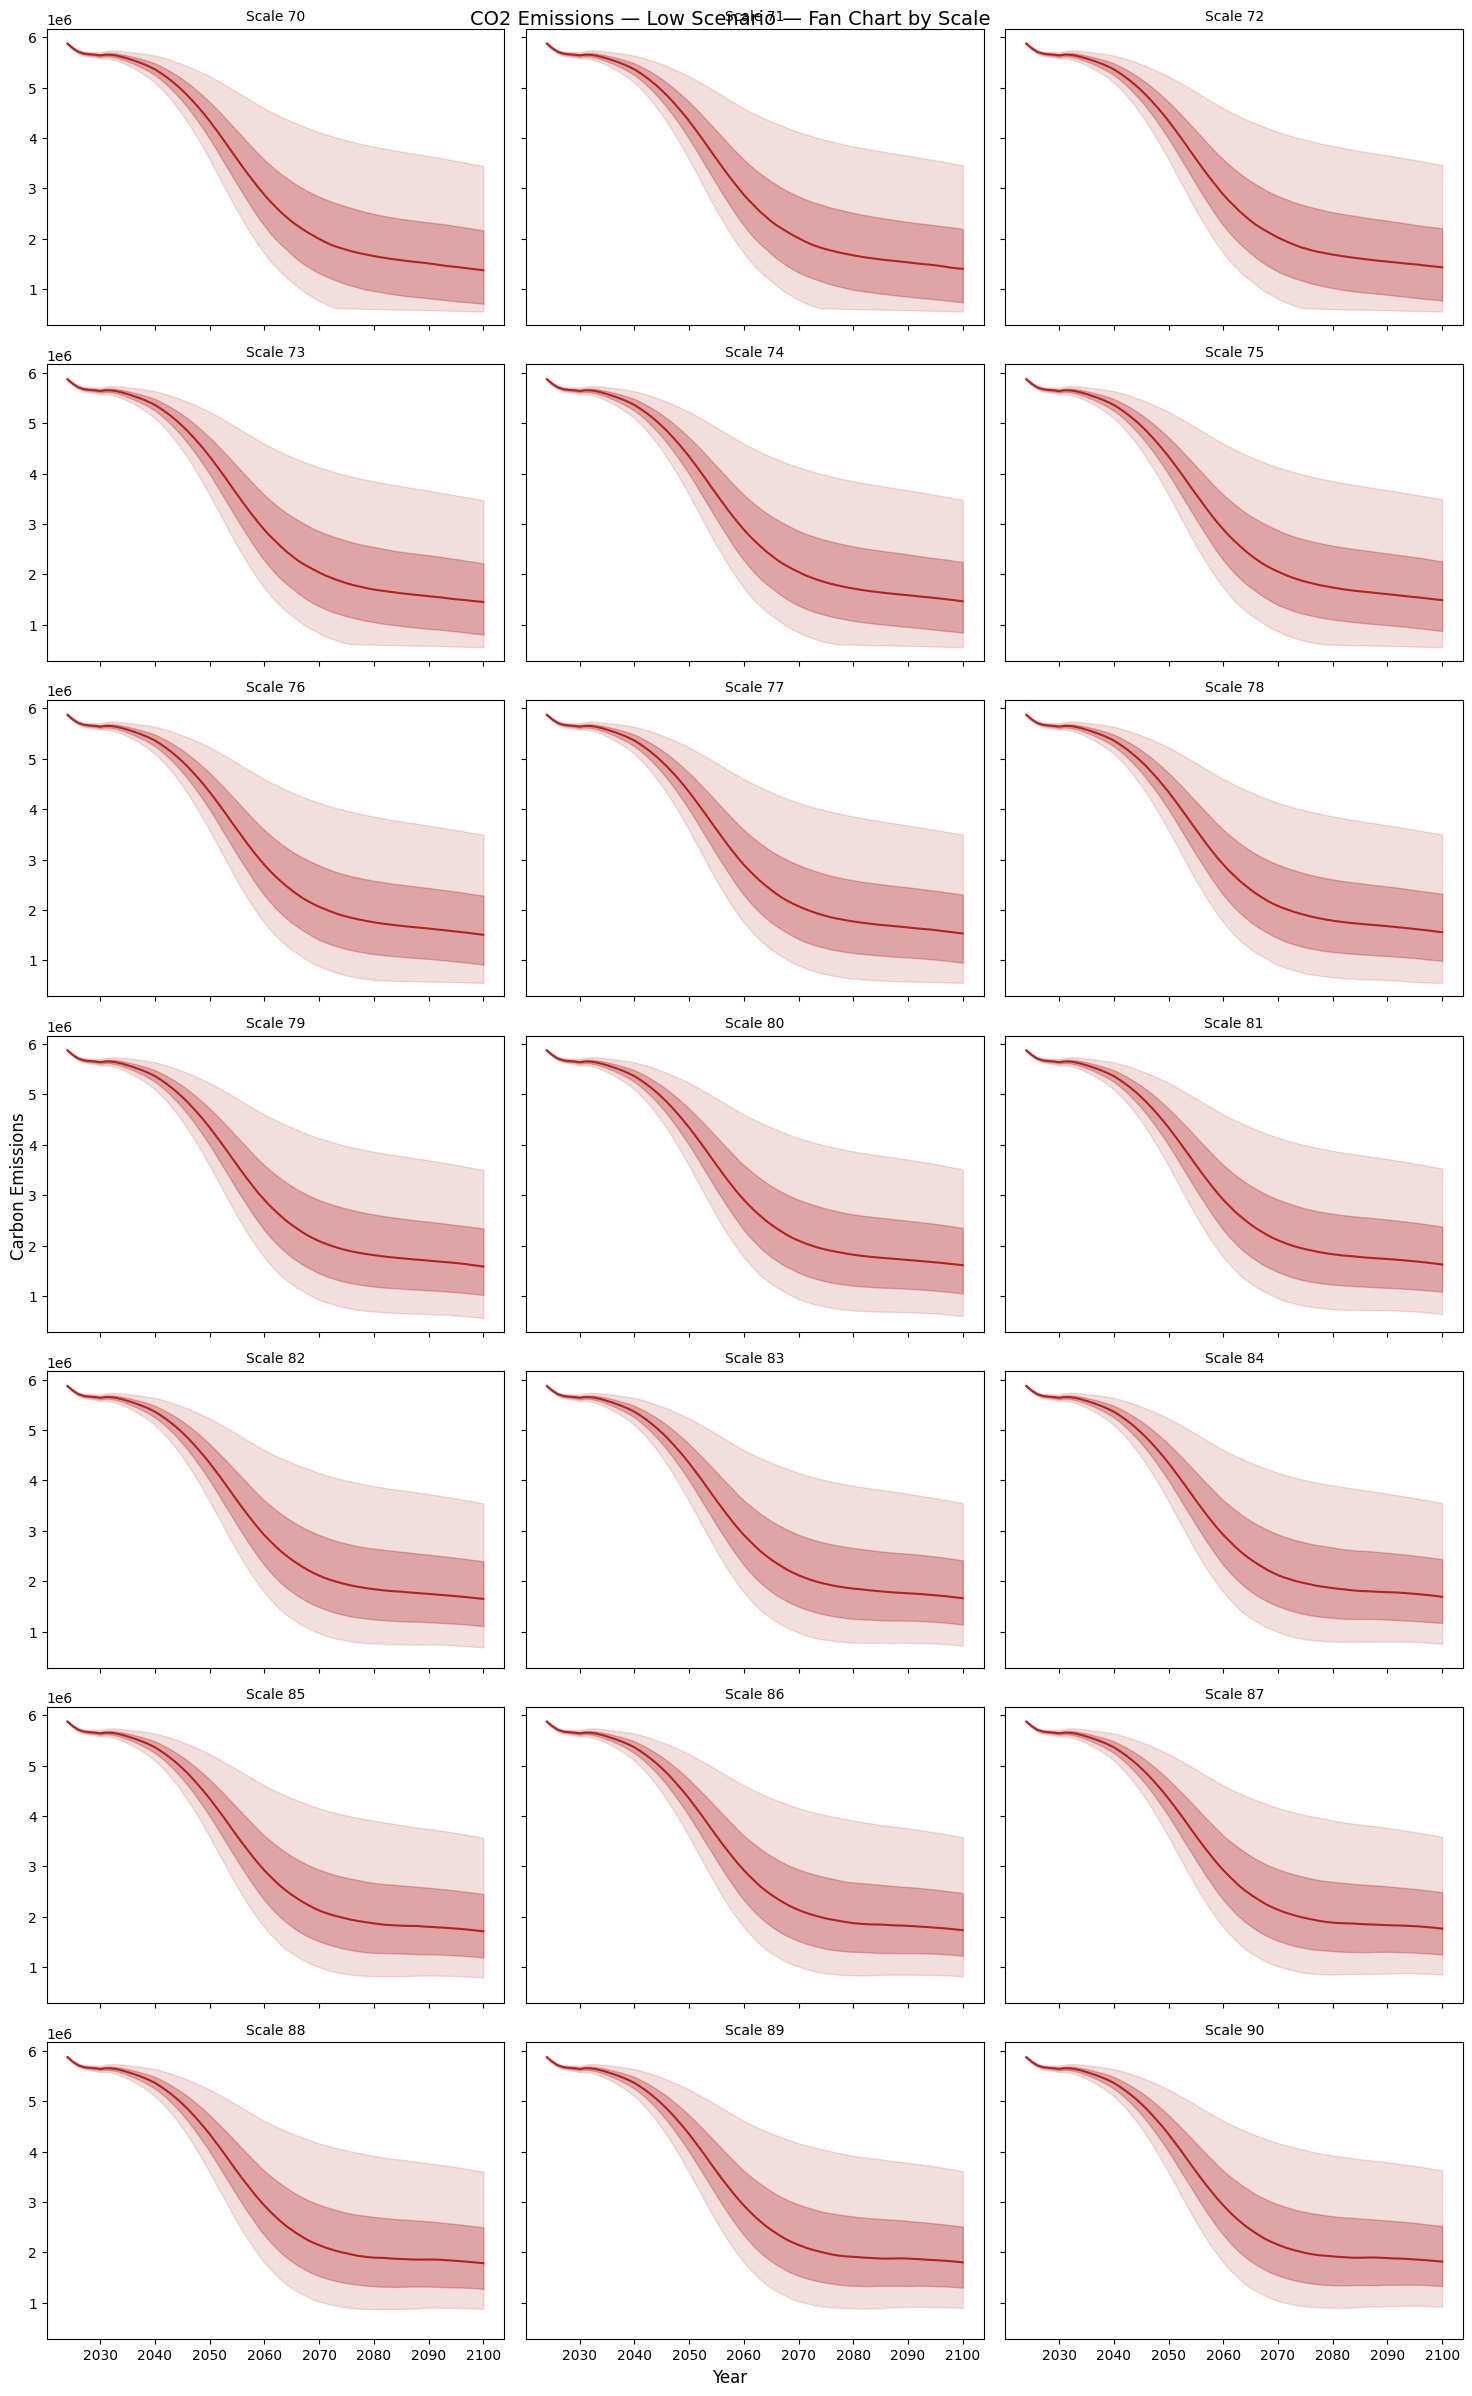

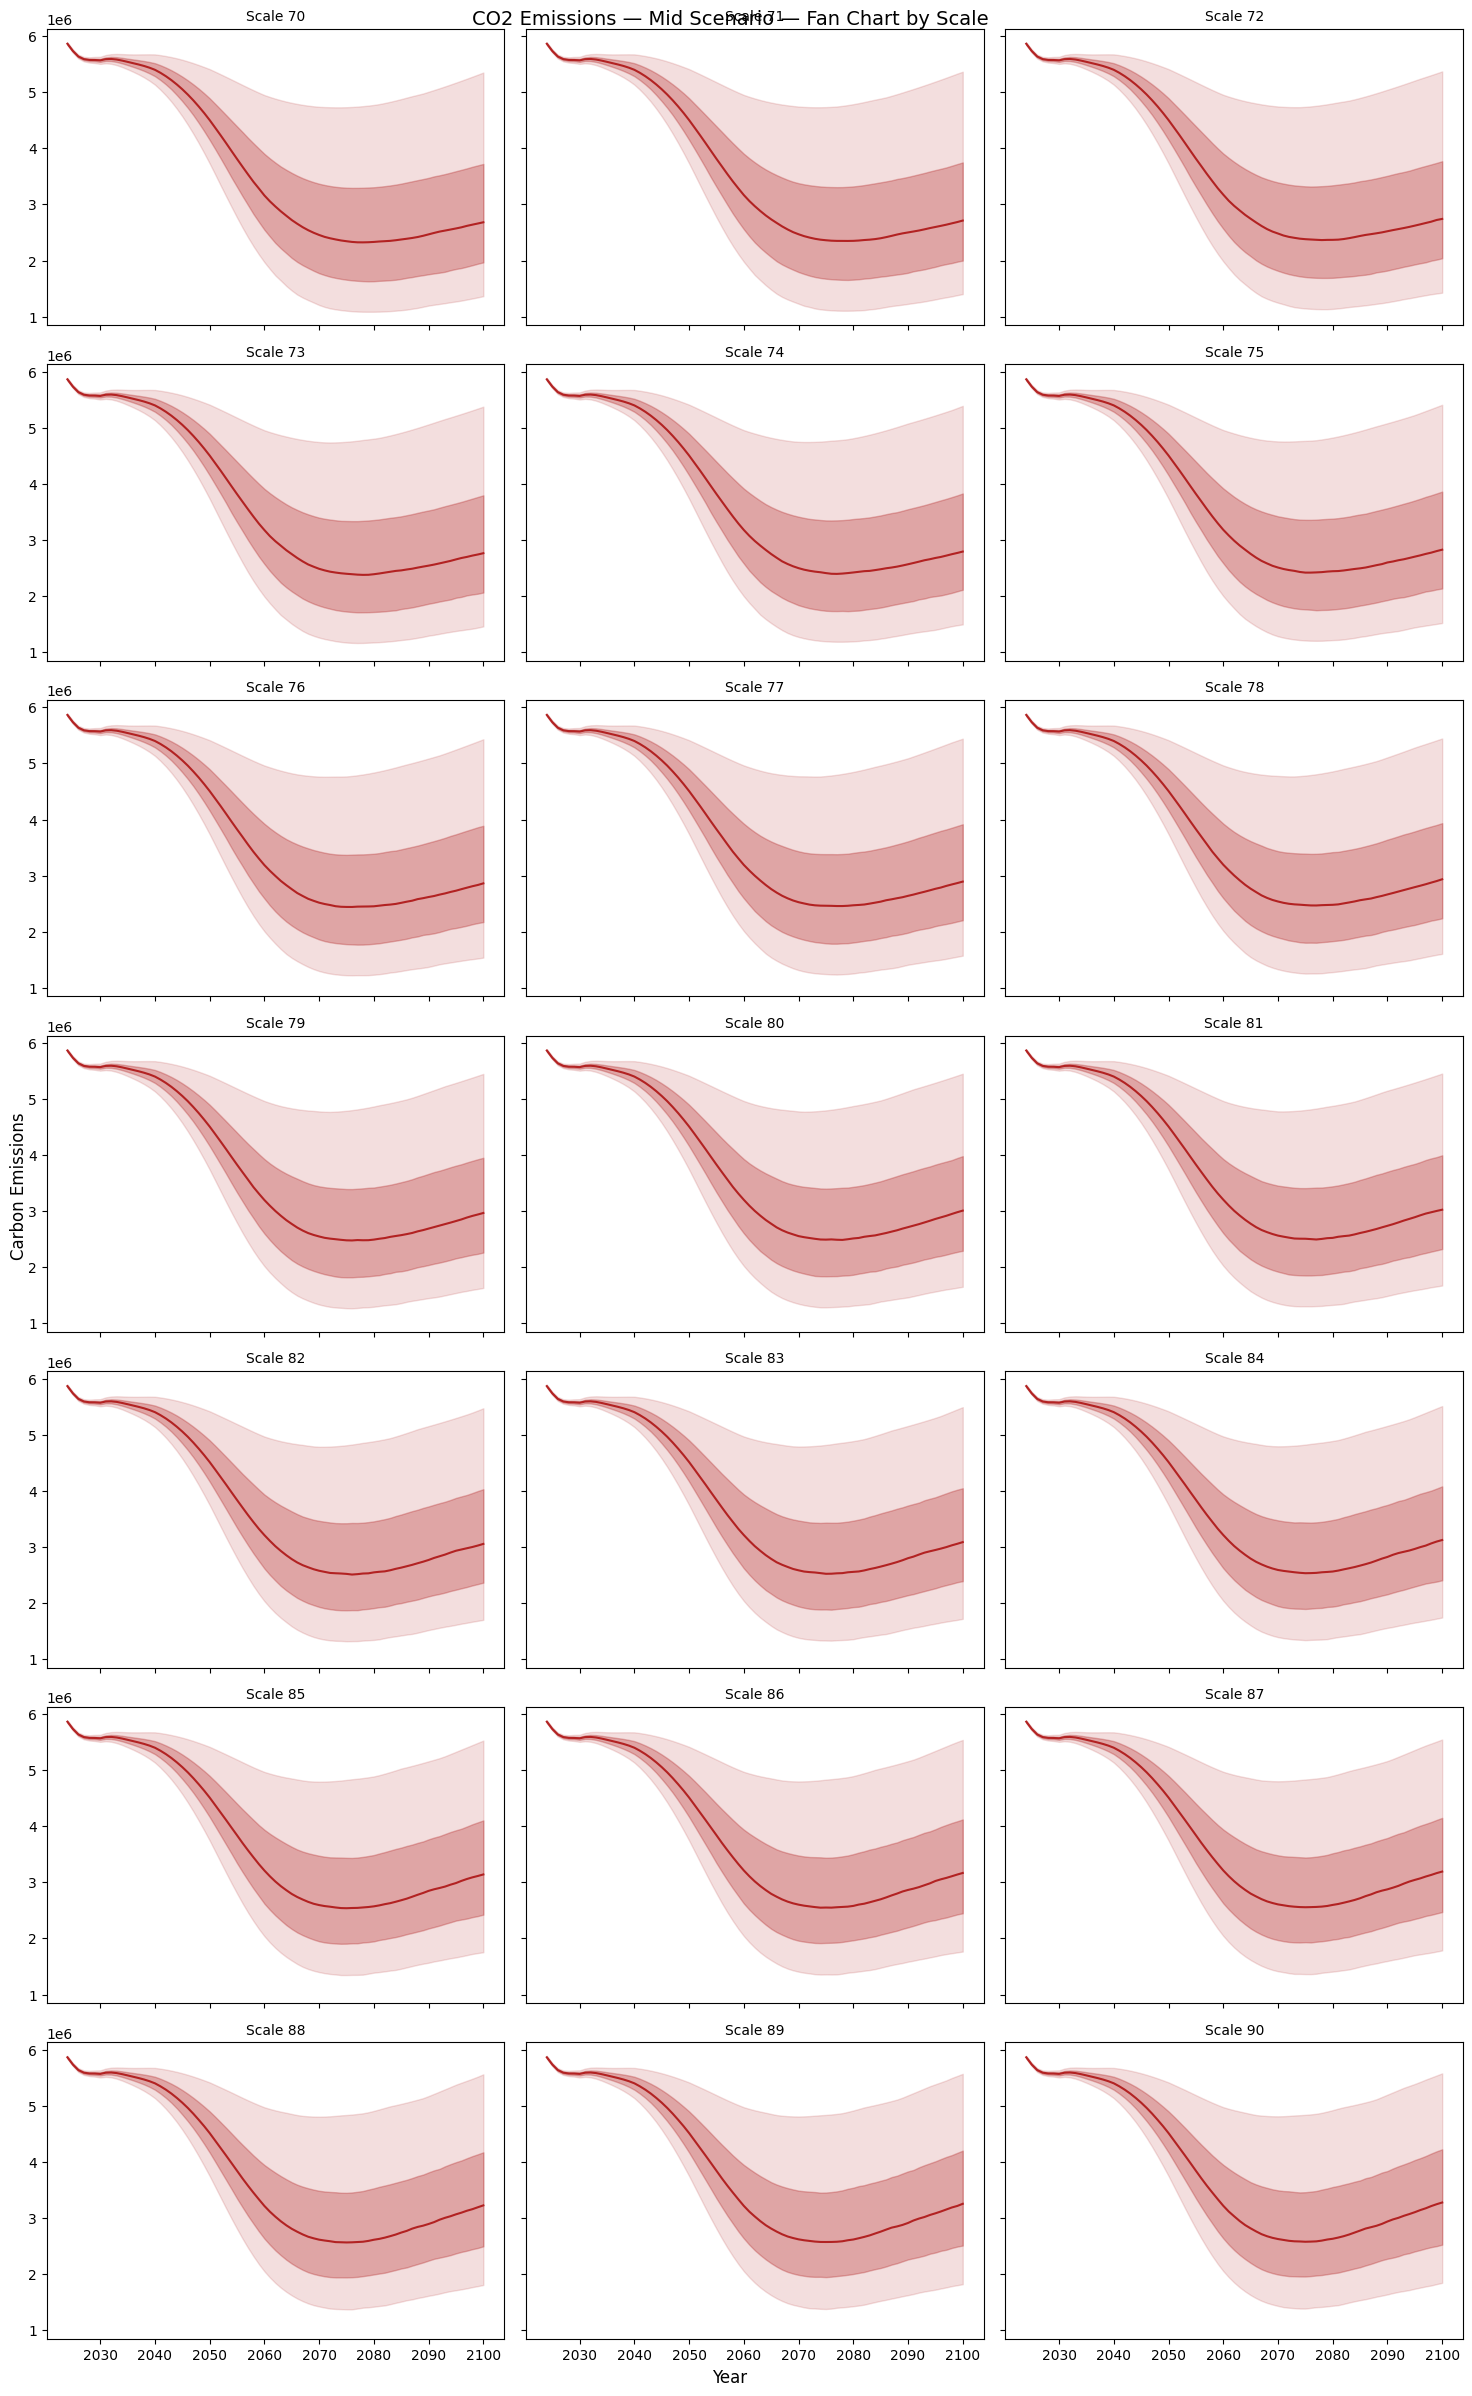

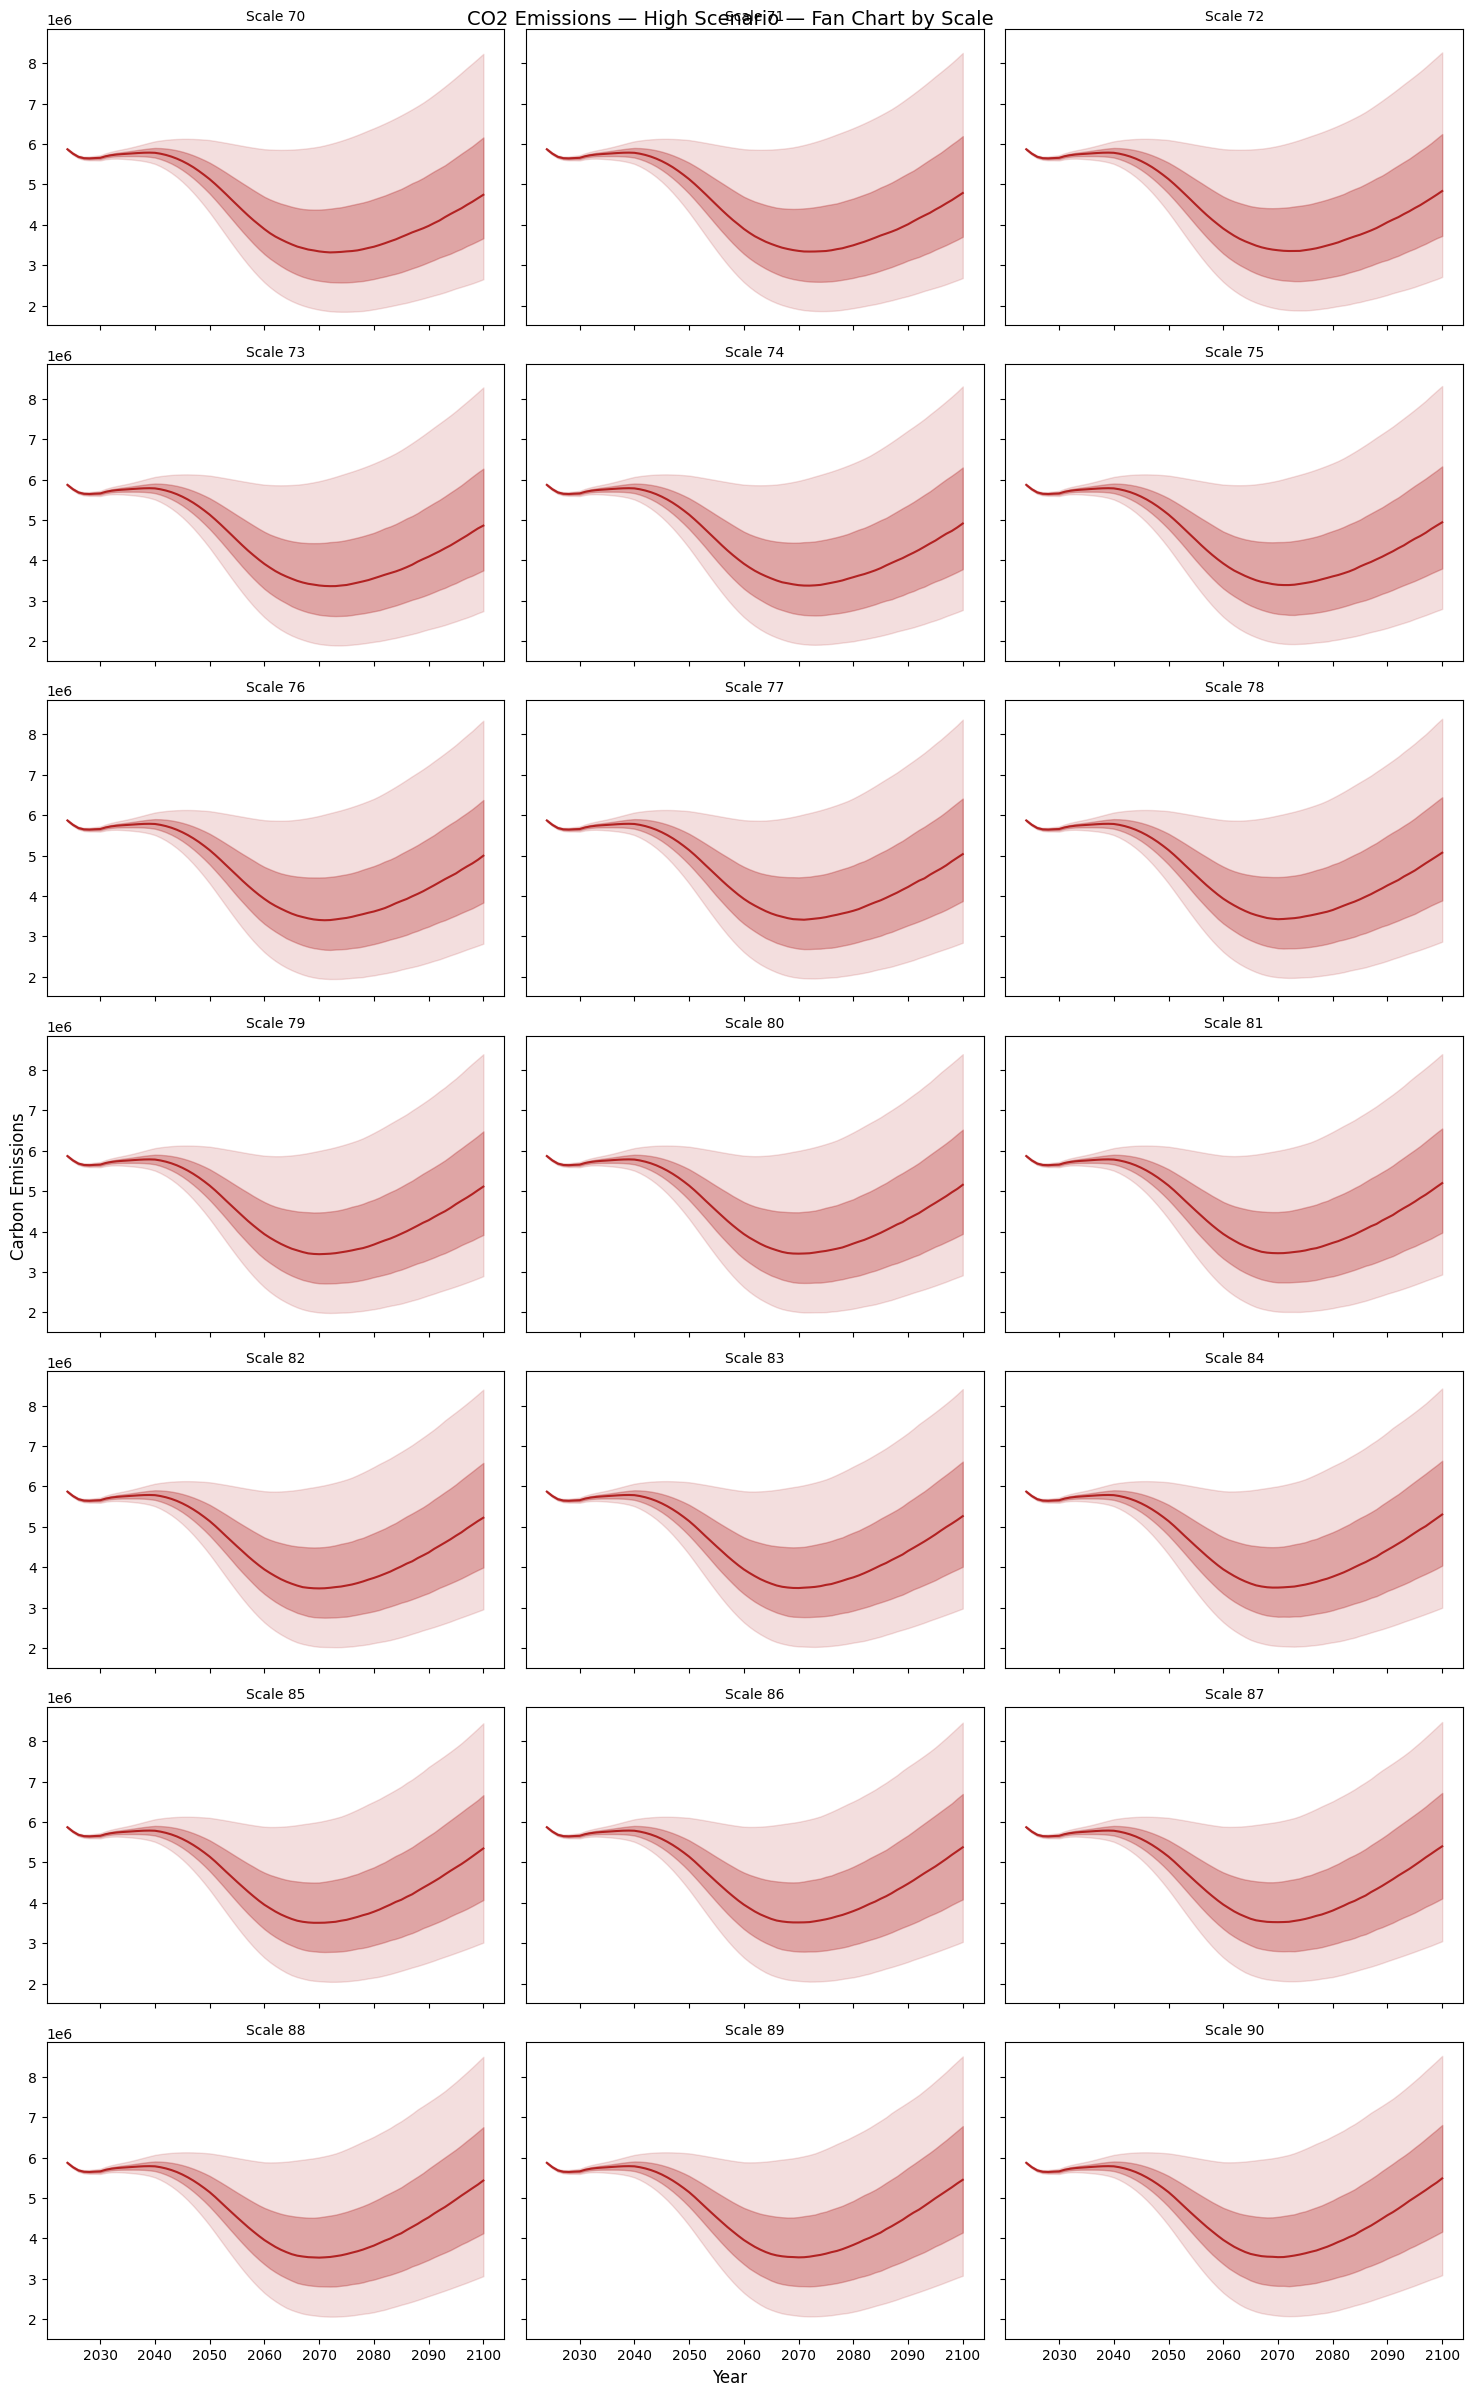

In [141]:
def plot_fan_chart_grid(df_qmc, value_col='carbon_emissions', title_prefix='CO2 Emissions',
                         percentiles=(5, 25, 50, 75, 95), color='firebrick', ncols=3):
    """
    Plots a grid of fan charts, one subplot per scale, for a single SSP scenario's df_qmc.
    """
    scales = sorted(df_qmc['scale'].unique())
    n_scales = len(scales)
    nrows = int(np.ceil(n_scales / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows), sharex=True, sharey=True)
    axes = np.atleast_1d(axes).ravel()

    for idx, scale in enumerate(scales):
        ax = axes[idx]
        subset = df_qmc[df_qmc['scale'] == scale]
        pivoted = subset.pivot(index='year', columns='draw_id', values=value_col)
        years_arr = pivoted.index.values
        pct_values = {p: pivoted.quantile(p / 100, axis=1).values for p in percentiles}

        if 5 in pct_values and 95 in pct_values:
            ax.fill_between(years_arr, pct_values[5], pct_values[95], color=color, alpha=0.15)
        if 25 in pct_values and 75 in pct_values:
            ax.fill_between(years_arr, pct_values[25], pct_values[75], color=color, alpha=0.3)
        if 50 in pct_values:
            ax.plot(years_arr, pct_values[50], color=color, linewidth=1.5)

        ax.set_title(f'Scale {int(scale)}', fontsize=10)

    # hide any unused subplots
    for idx in range(n_scales, len(axes)):
        axes[idx].axis('off')

    fig.suptitle(f'{title_prefix} — Fan Chart by Scale', fontsize=14)
    fig.supxlabel('Year')
    fig.supylabel(value_col.replace('_', ' ').title())
    plt.tight_layout()
    plt.show()
    return fig, axes


# one grid per SSP scenario
fig_low, axes_low   = plot_fan_chart_grid(df_qmc_low,  title_prefix='CO2 Emissions — Low Scenario')
fig_mid, axes_mid   = plot_fan_chart_grid(df_qmc_mid,  title_prefix='CO2 Emissions — Mid Scenario')
fig_high, axes_high = plot_fan_chart_grid(df_qmc_high, title_prefix='CO2 Emissions — High Scenario')

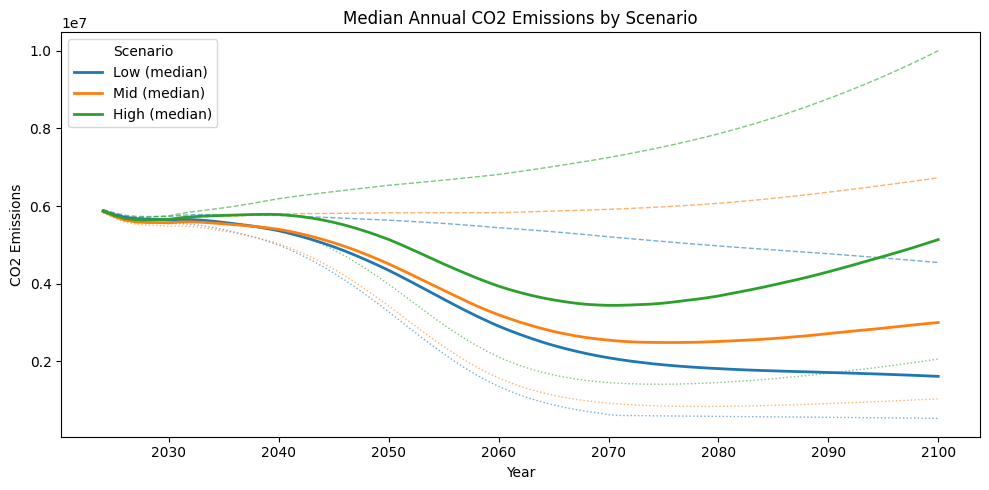

In [143]:
def emissions_summary_by_year(df_qmc):
    """Median, min, and max carbon_emissions per year, across all scales and draws."""
    grouped = df_qmc.groupby('year')['carbon_emissions']
    return pd.DataFrame({
        'median': grouped.median(),
        'min': grouped.min(),
        'max': grouped.max(),
    })


def plot_emissions_comparison(df_qmc_low, df_qmc_mid, df_qmc_high,
                                title='Median Annual CO2 Emissions by Scenario'):
    summaries = {
        'Low':  emissions_summary_by_year(df_qmc_low),
        'Mid':  emissions_summary_by_year(df_qmc_mid),
        'High': emissions_summary_by_year(df_qmc_high),
    }

    colors = {'Low': 'tab:blue', 'Mid': 'tab:orange', 'High': 'tab:green'}

    fig, ax = plt.subplots(figsize=(10, 5))

    for label, summary in summaries.items():
        color = colors[label]
        ax.plot(summary.index, summary['median'], label=f'{label} (median)',
                linewidth=2, color=color, zorder=5)
        ax.plot(summary.index, summary['max'], linestyle='--', linewidth=1,
                color=color, alpha=0.6, zorder=3)
        ax.plot(summary.index, summary['min'], linestyle=':', linewidth=1,
                color=color, alpha=0.6, zorder=3)

    ax.set_xlabel('Year')
    ax.set_ylabel('CO2 Emissions')
    ax.set_title(title)
    ax.legend(title='Scenario', loc='upper left')

    plt.tight_layout()
    plt.show()
    return fig, ax


fig, ax = plot_emissions_comparison(df_qmc_low, df_qmc_mid, df_qmc_high)

### Old LCA

In [ ]:
# flows = all_flows.loc[2024:2100]

# # Find all ssp suffixes present (ssp1, ssp2, ...) based on inflow_ column names
# ssp_names = sorted({col.replace('inflow_', '') for col in flows.columns if col.startswith('inflow_')})

# emissions = pd.DataFrame(index=flows.index)

# for ssp in ssp_names:
#     inflow = flows[f'inflow_{ssp}']
#     outflow = flows[f'outflow_{ssp}']
    
#     # Typical (virgin) steel production emissions
#     emissions[f'typical_co2_{ssp}'] = inflow * production_co2
    
#     # Reused steel emissions: outflow fabricated + remainder produced new
#     emissions[f'reused_co2_{ssp}'] = (outflow * fabrication_co2) + ((inflow - outflow) * production_co2)


# emissions = emissions/1e3

# emissions

,typical_co2_ssp1,reused_co2_ssp1,typical_co2_ssp2,reused_co2_ssp2,typical_co2_ssp3,reused_co2_ssp3,typical_co2_ssp4,reused_co2_ssp4,typical_co2_ssp5,reused_co2_ssp5
Year,,,,,,,,,,
2024,5.777099,2.787505,5.778828,2.789234,5.826249,2.836654,5.806901,2.817306,5.656915,2.667322
2025,5.684040,2.643994,5.687038,2.646993,5.762652,2.722603,5.734193,2.694146,5.491999,2.451962
2026,5.645626,2.555528,5.648917,2.558818,5.736041,2.645929,5.708306,2.618199,5.419677,2.329612
2027,5.641842,2.502127,5.644136,2.504420,5.731480,2.591730,5.712631,2.572895,5.405178,2.265547
2028,5.654468,2.465603,5.654145,2.465278,5.734983,2.546052,5.731802,2.542894,5.418868,2.230170
...,...,...,...,...,...,...,...,...,...,...
2095,7.700664,2.550301,6.650042,1.612121,4.706187,-0.217222,9.558840,4.216447,7.753863,2.744859
2096,7.776834,2.610974,6.688342,1.640186,4.682836,-0.243122,9.688321,4.321786,7.855849,2.834170
2097,7.856958,2.675634,6.727334,1.669136,4.659241,-0.268721,9.821644,4.430719,7.962811,2.928404


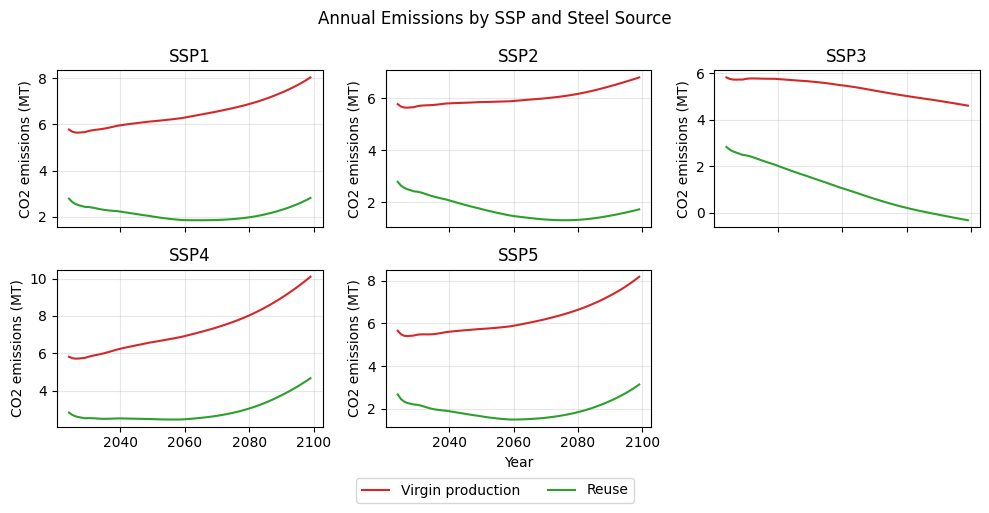

In [ ]:
# fig, axes = plt.subplots(2, 3, figsize=(10, 5), sharex=True)
# axes = axes.flatten()

# for ax, ssp in zip(axes, ssp_names):
#     ax.plot(emissions.index, emissions[f'typical_co2_{ssp}'], label='Virgin production', color='#d62728')
#     ax.plot(emissions.index, emissions[f'reused_co2_{ssp}'], label='Reuse', color='#2ca02c')
#     ax.set_title(ssp.upper())
#     ax.set_ylabel('CO2 emissions (MT)')
#     ax.grid(alpha=0.3)

# # Hide any unused subplot(s) — e.g. if you have 5 SSPs in a 6-slot grid
# for ax in axes[len(ssp_names):]:
#     ax.axis('off')

# # Shared legend, built from the first panel's lines
# handles, labels = axes[0].get_legend_handles_labels()
# fig.legend(handles, labels, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.02), fontsize=10)
# fig.suptitle('Annual Emissions by SSP and Steel Source')

# for ax in axes[-2:]:
#     if ax.get_visible():
#         ax.set_xlabel('Year')

# plt.tight_layout(rect=[0, 0.03, 1, 1])  # leave room at bottom for legend
# plt.savefig('emissions_by_ssp.png', dpi=150, bbox_inches='tight')
# plt.show()